In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import scanpy.external as sce
import scipy
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=600)
    
import matplotlib.pyplot as pl
from matplotlib import rcParams

import os

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/_utils/__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/__init__.py:36: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/logging.py:151: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  yield dist_name, imp.__version__
/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/tqdm/a

scanpy==1.10.4 anndata==0.12.10 umap==0.5.7 numpy==2.4.2 scipy==1.17.1 pandas==2.3.3 scikit-learn==1.6.1 statsmodels==0.14.4 igraph==0.11.8 pynndescent==0.5.13


In [135]:
adata=sc.read('/mnt/c/Users/hyj/Downloads/MCAD.h5ad')
adata

AnnData object with n_obs × n_vars = 51195 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [136]:
adata.obs.dataset

P1_T_AAACCCAAGCTCATAC-1_P1_T        GSE236698
P1_T_AAACCCAAGGATATGT-1_P1_T        GSE236698
P1_T_AAACCCAAGTATAACG-1_P1_T        GSE236698
P1_T_AAACCCACAAATGGCG-1_P1_T        GSE236698
P1_T_AAACCCACAACTAGAA-1_P1_T        GSE236698
                                      ...    
SMC20T_TTTGTCACAGATCTGT-1_SMC20T          SMC
SMC20T_TTTGTCAGTACCGTAT-1_SMC20T          SMC
SMC20T_TTTGTCAGTCAAACTC-1_SMC20T          SMC
SMC20T_TTTGTCATCACGCGGT-1_SMC20T          SMC
SMC20T_TTTGTCATCGCCAAAT-1_SMC20T          SMC
Name: dataset, Length: 51195, dtype: category
Categories (2, object): ['GSE236698', 'SMC']

normalizing counts per cell
    finished (0:00:02)


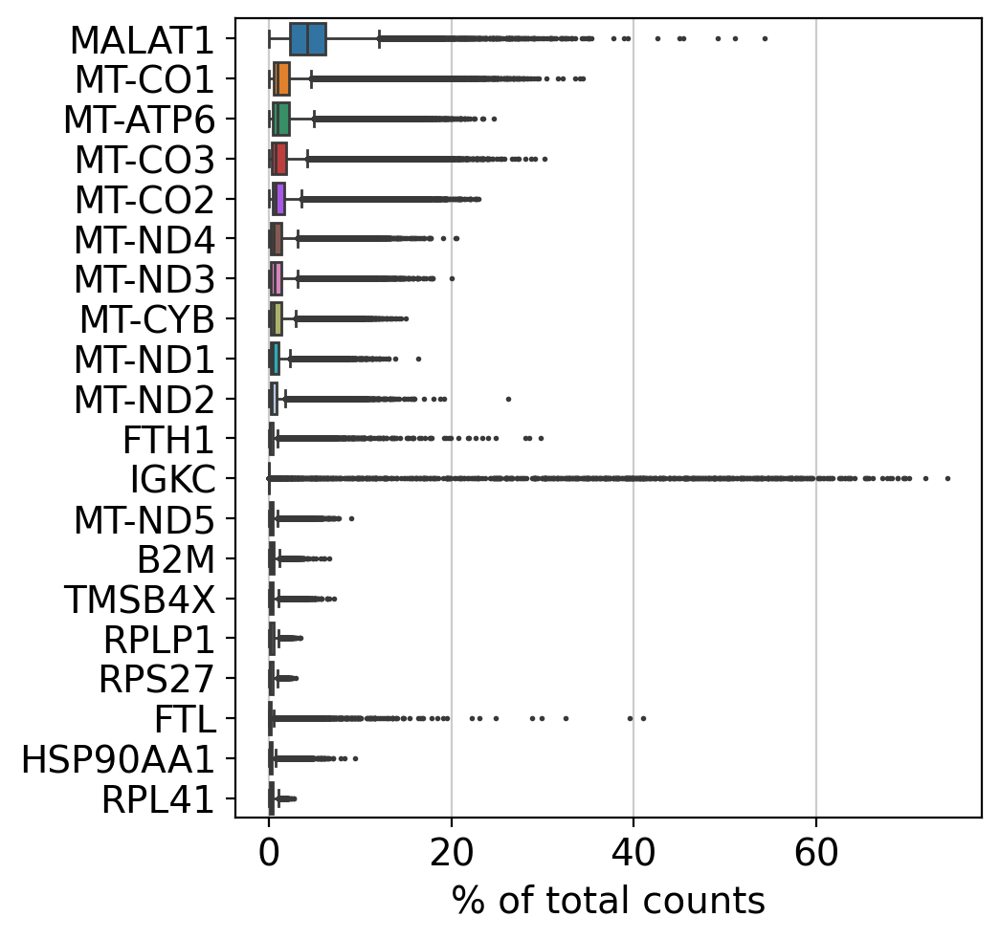

filtered out 573 cells that have less than 100 genes expressed
filtered out 9818 genes that are detected in less than 25 cells


In [137]:
sc.pl.highest_expr_genes(adata, n_top=20)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=25)

In [138]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
adata.var['rpl'] = adata.var_names.str.startswith('RPL')
adata.var['rps'] = adata.var_names.str.startswith('RPS')
adata

AnnData object with n_obs × n_vars = 50622 × 28788
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

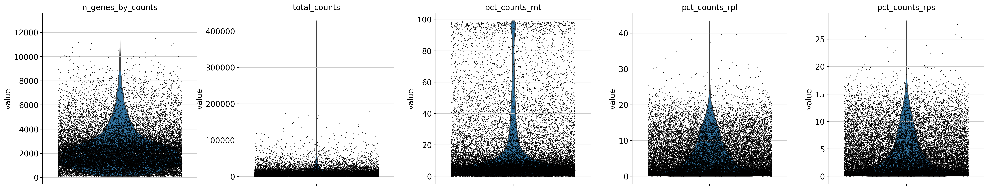

AnnData object with n_obs × n_vars = 50622 × 28788
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [139]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
adata

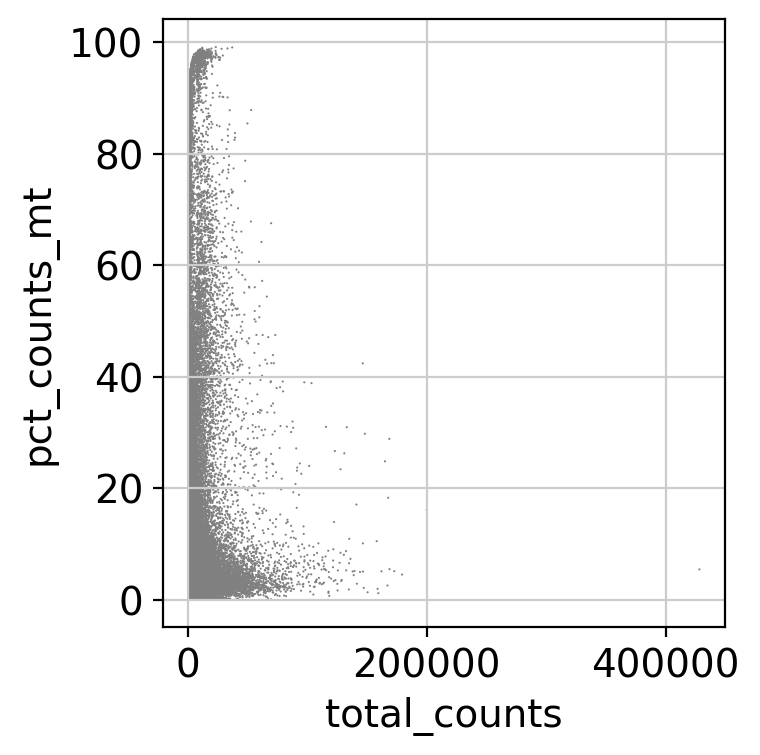

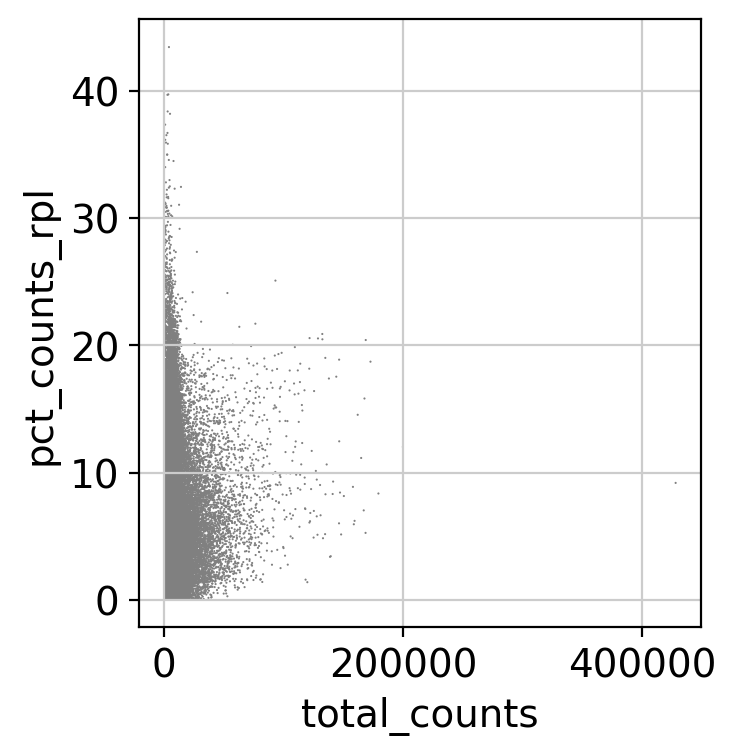

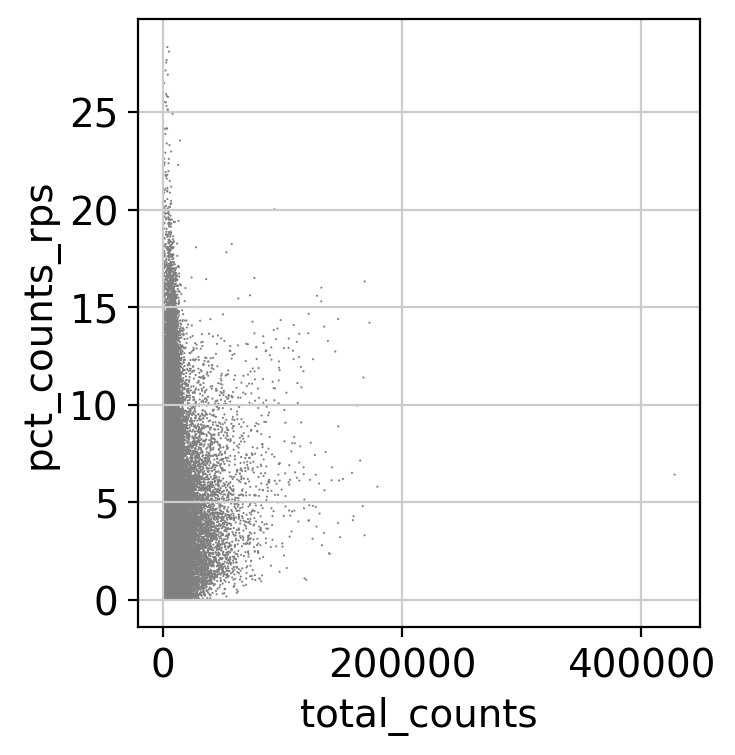

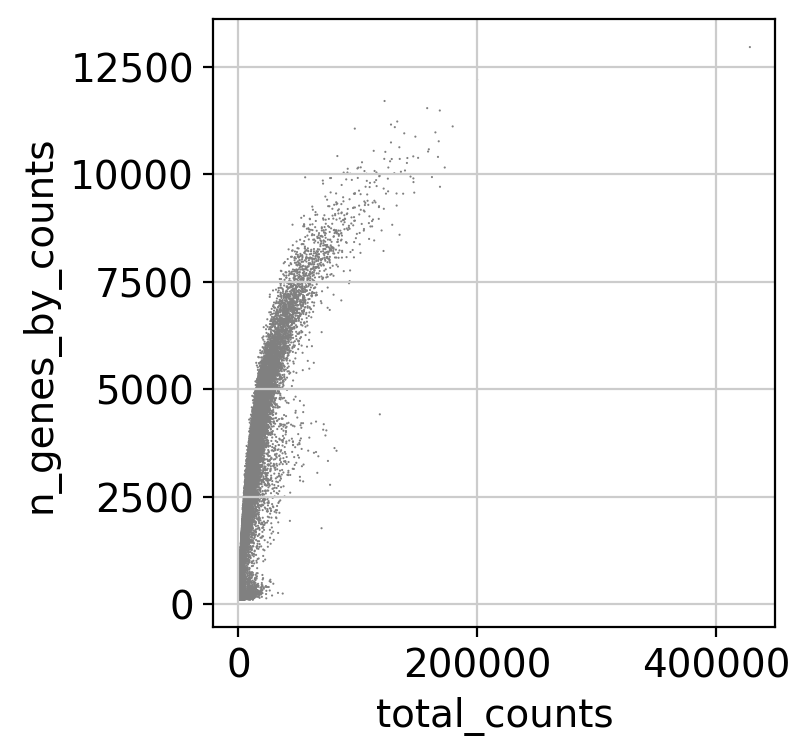

In [140]:
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

In [141]:
adata = adata[adata.obs.n_genes_by_counts < 12000, :]
adata = adata[adata.obs.pct_counts_mt < 50, :]
adata = adata[adata.obs.pct_counts_rpl < 50, :]
adata = adata[adata.obs.pct_counts_rps < 50, :]
adata

View of AnnData object with n_obs × n_vars = 46968 × 28788
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [142]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 46968 × 28788
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

extracting highly variable genes
    finished (0:00:03)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


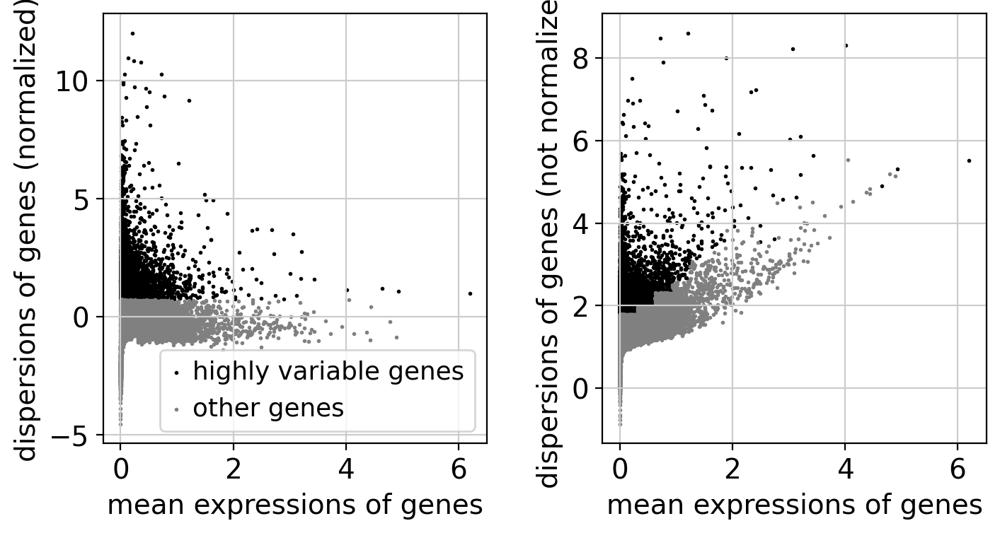

5000


AnnData object with n_obs × n_vars = 46968 × 28788
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [143]:
sc.pp.highly_variable_genes(adata, n_top_genes=5000)
sc.pl.highly_variable_genes(adata)
print(sum(adata.var.highly_variable))
adata

In [144]:
adata.raw=adata

In [145]:
adata = adata[:, adata.var.highly_variable]
adata

View of AnnData object with n_obs × n_vars = 46968 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [146]:
sc.pp.regress_out(adata, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=96)
sc.pp.scale(adata, max_value=10)
adata

regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']


/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:672: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


    sparse input is densified and may lead to high memory use
    finished (0:01:00)


AnnData object with n_obs × n_vars = 46968 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [147]:
sc.tl.pca(adata, svd_solver='arpack')
sce.pp.harmony_integrate(adata, key='sample', basis='X_pca', adjusted_basis='X_pca_harmony')
adata.obsm['X_pca']=adata.obsm['X_pca_harmony']
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50, knn=True)
sc.tl.leiden(adata, resolution=1, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata)
adata

computing PCA
    with n_comps=50
    finished (0:00:19)


2025-10-17 15:03:49,953 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-10-17 15:03:56,722 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-10-17 15:03:56,955 - harmonypy - INFO - Iteration 1 of 10
2025-10-17 15:04:23,616 - harmonypy - INFO - Iteration 2 of 10
2025-10-17 15:04:51,173 - harmonypy - INFO - Iteration 3 of 10
2025-10-17 15:05:18,599 - harmonypy - INFO - Converged after 3 iterations


computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:20)
running Leiden clustering
    finished: found 27 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:03)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:30)


AnnData object with n_obs × n_vars = 46968 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

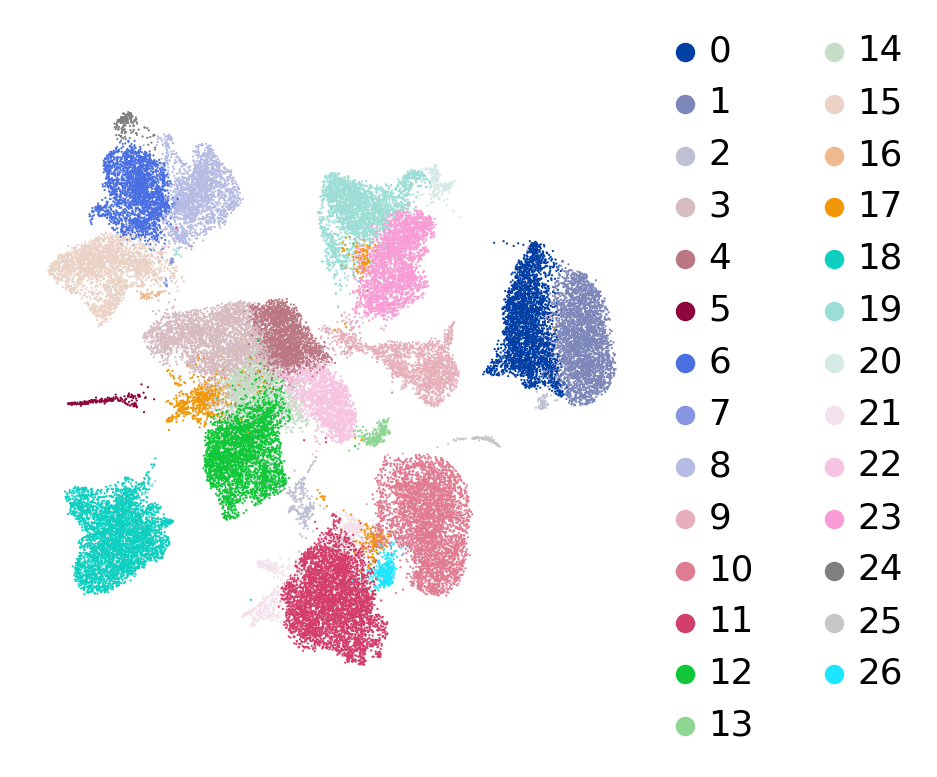

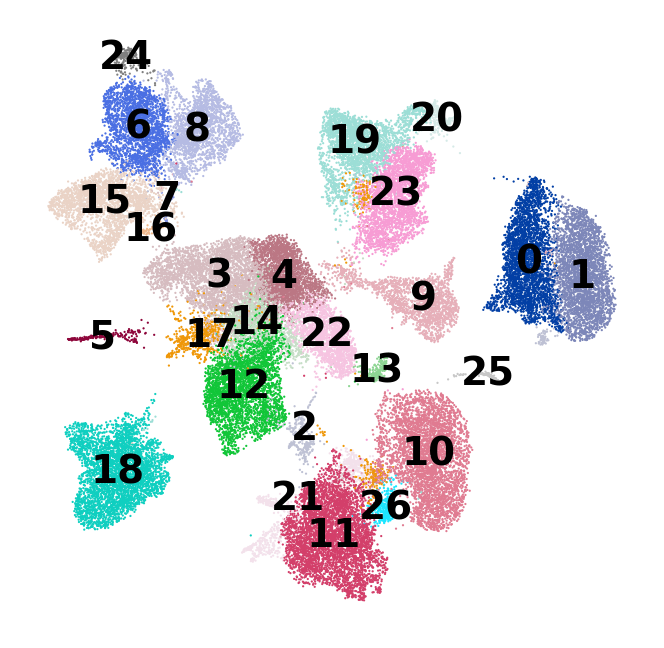

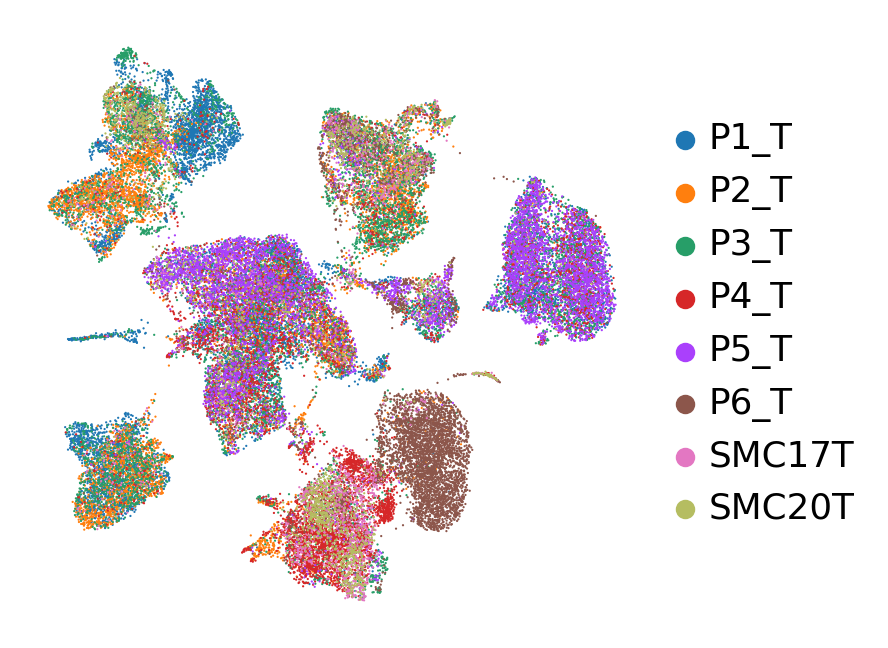

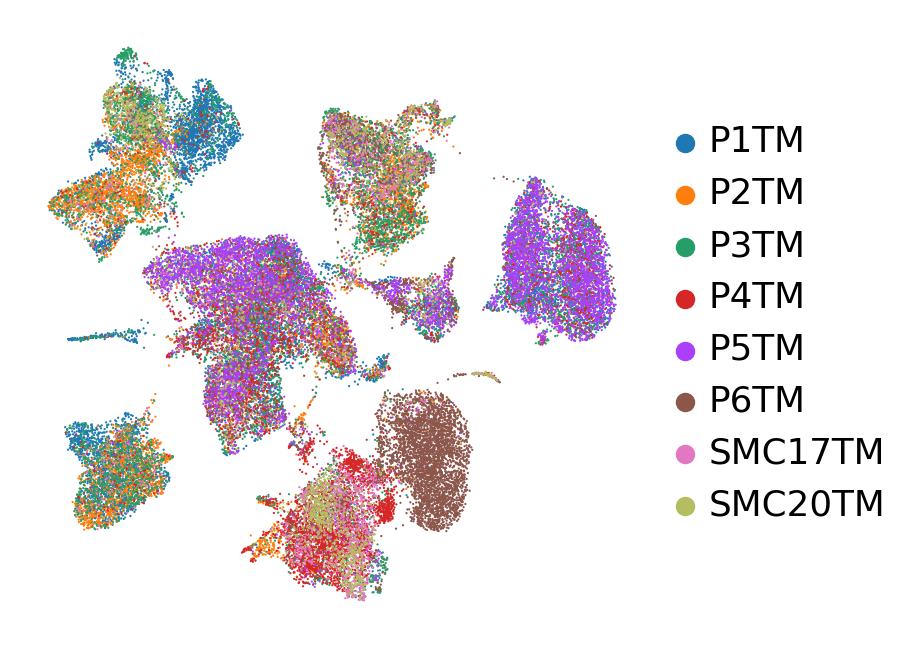

In [251]:
sc.pl.umap(adata, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='1.pdf')
sc.pl.umap(adata, color=['leiden'], legend_loc='on data', frameon=False, title='', use_raw=True)
sc.pl.umap(adata, color=['sample'], legend_loc='right margin', frameon=False, title='', use_raw=True)
sc.pl.umap(adata, color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='5.pdf')

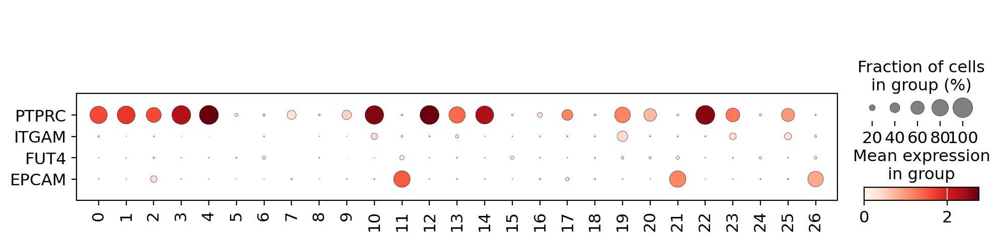

In [149]:
sc.pl.dotplot(adata, var_names=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], groupby='leiden', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

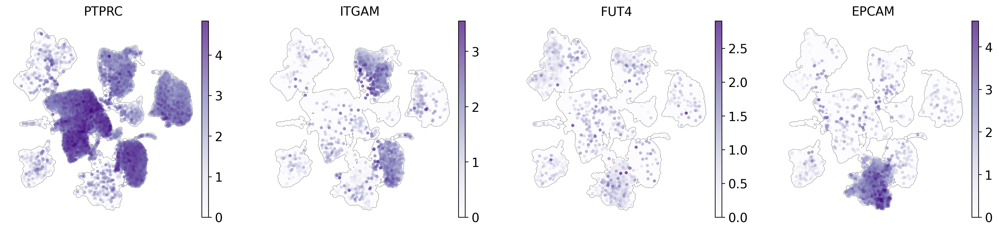

In [150]:
sc.pl.umap(adata, color=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [151]:
adata.write('/mnt/c/Users/hyj/Downloads/MCAD_adata_1.h5ad', compression='gzip')

In [19]:
# make adata_sub by keeping EPCAM+ cells

In [252]:
raw = sc.read('/mnt/c/Users/hyj/Downloads/MCAD.h5ad')
raw

AnnData object with n_obs × n_vars = 51195 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [253]:
adata = sc.read('/mnt/c/Users/hyj/Downloads/MCAD_adata_1.h5ad')
adata

AnnData object with n_obs × n_vars = 46968 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'leiden'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [254]:
raw.obs['leiden']=adata.obs['leiden']

In [255]:
adata_sub=raw[raw.obs['leiden'].isin(['2', '11', '21', '26'])]
adata_sub

View of AnnData object with n_obs × n_vars = 5852 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden'
    var: 'gene_ids'

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


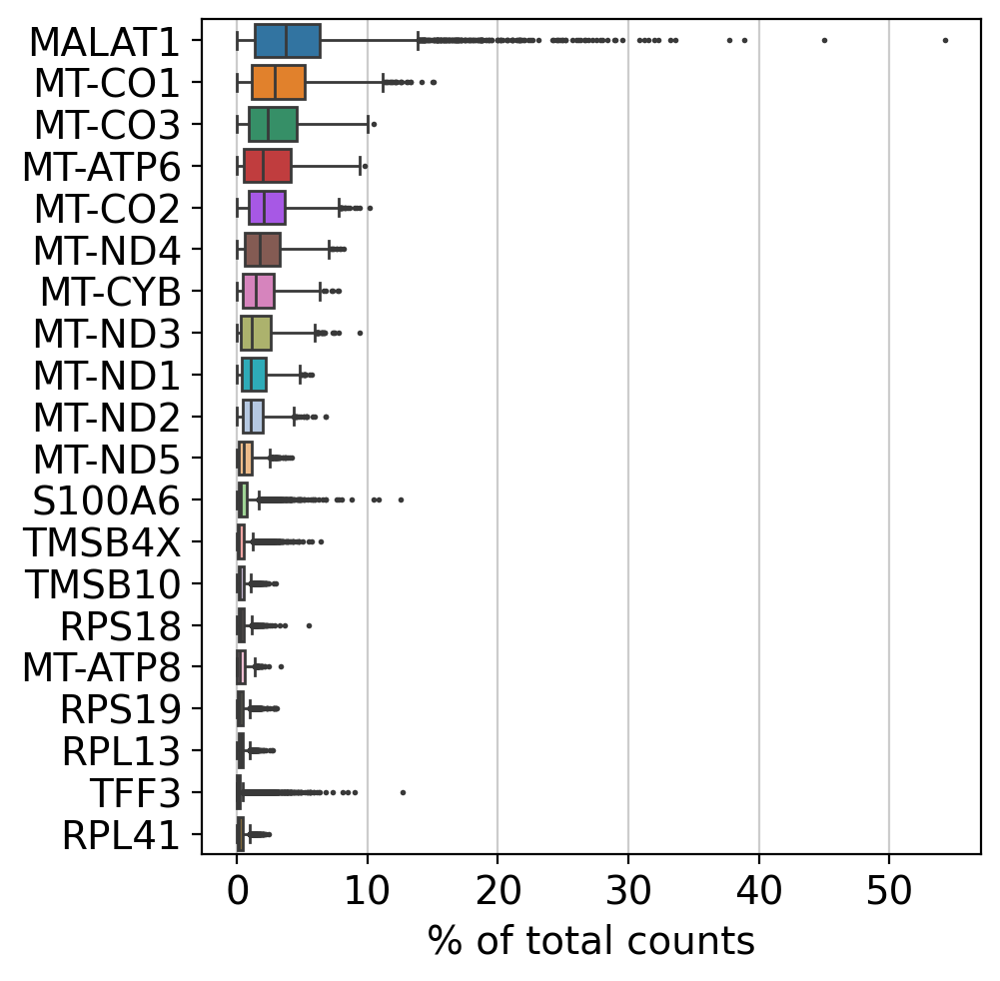

filtered out 16367 genes that are detected in less than 25 cells


AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells'

In [256]:
sc.pl.highest_expr_genes(adata_sub, n_top=20)
sc.pp.filter_cells(adata_sub, min_genes=100)
sc.pp.filter_genes(adata_sub, min_cells=25)
adata_sub

In [257]:
adata_sub.var['mt'] = adata_sub.var_names.str.startswith('MT-')
adata_sub.var['rpl'] = adata_sub.var_names.str.startswith('RPL')
adata_sub.var['rps'] = adata_sub.var_names.str.startswith('RPS')
adata_sub

AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

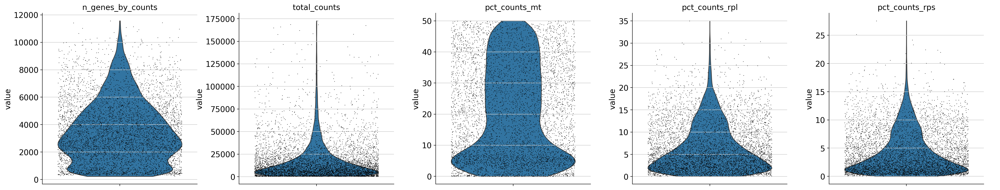

AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [258]:
sc.pp.calculate_qc_metrics(adata_sub, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata_sub, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
adata_sub

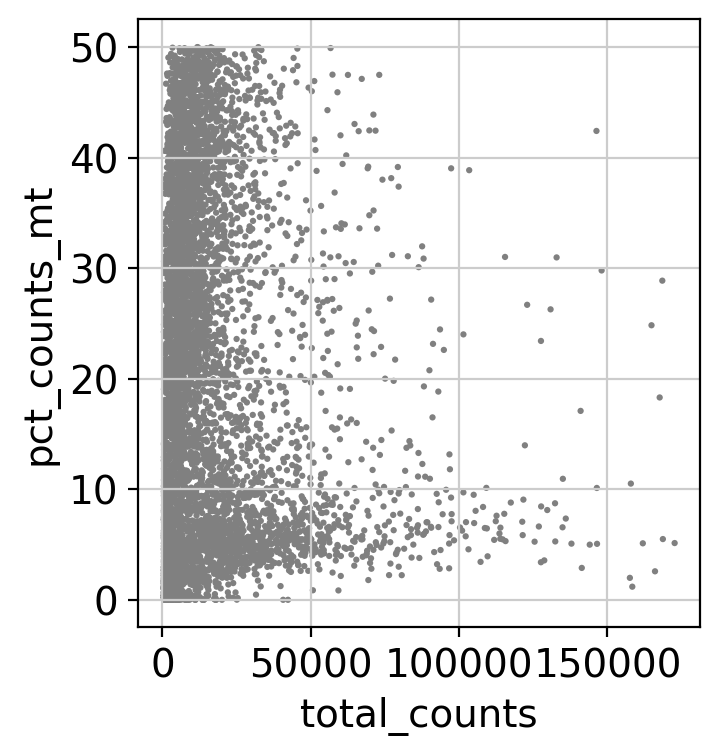

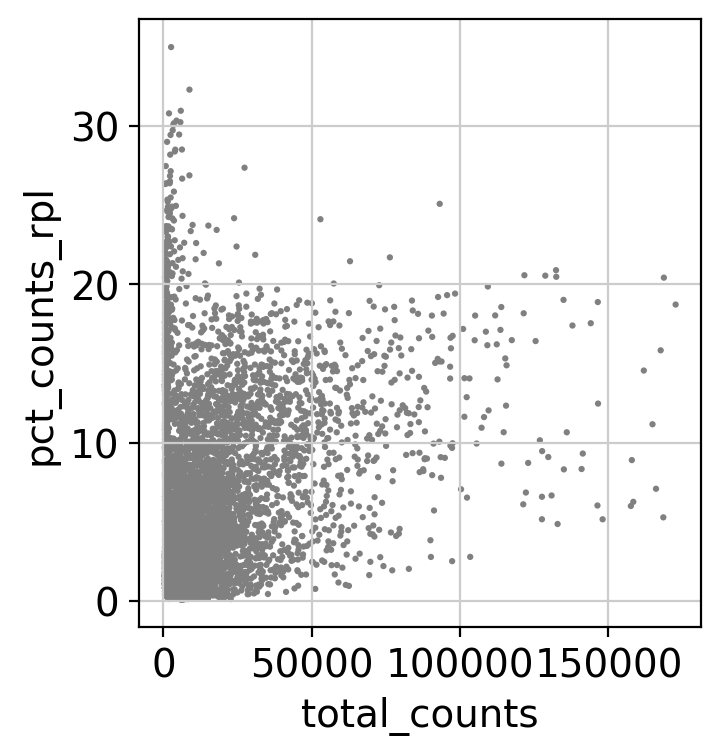

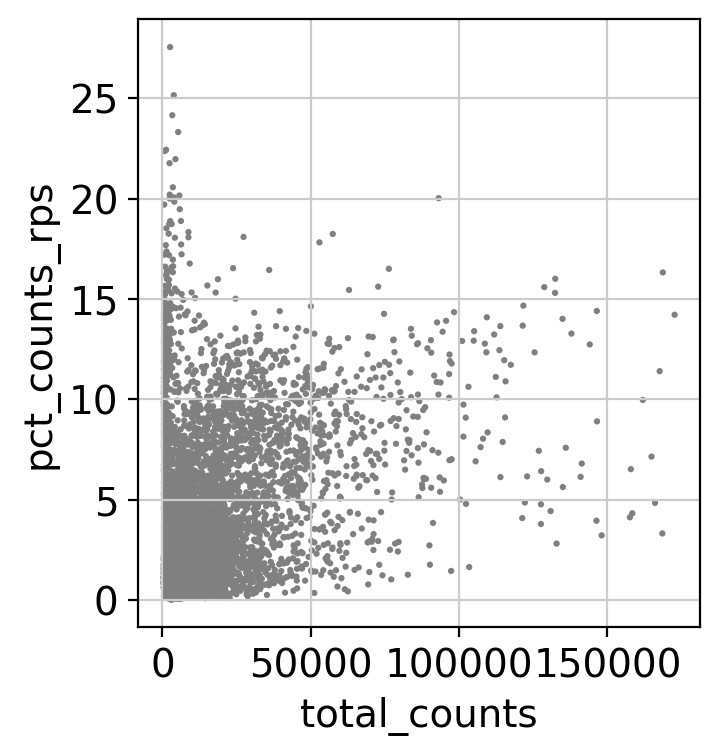

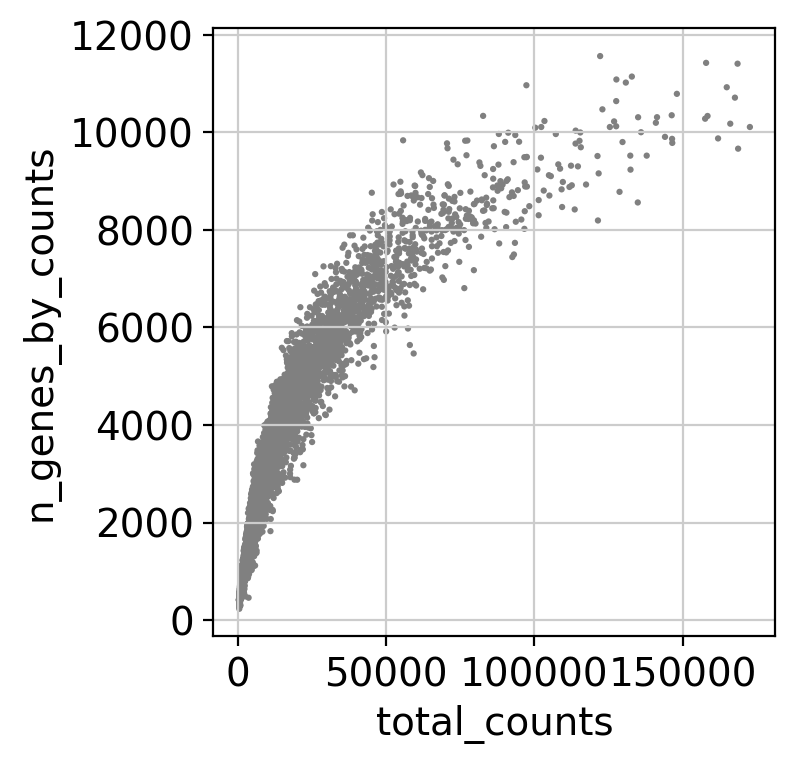

In [259]:
sc.pl.scatter(adata_sub, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata_sub, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata_sub, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata_sub, x='total_counts', y='n_genes_by_counts')

In [260]:
adata_sub = adata_sub[adata_sub.obs.n_genes_by_counts < 12000, :]
adata_sub = adata_sub[adata_sub.obs.pct_counts_mt < 50, :]
adata_sub = adata_sub[adata_sub.obs.pct_counts_rpl < 50, :]
adata_sub = adata_sub[adata_sub.obs.pct_counts_rps < 50, :]
adata_sub

View of AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [261]:
sc.pp.normalize_total(adata_sub, target_sum=1e4)
sc.pp.log1p(adata_sub)
adata_sub

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


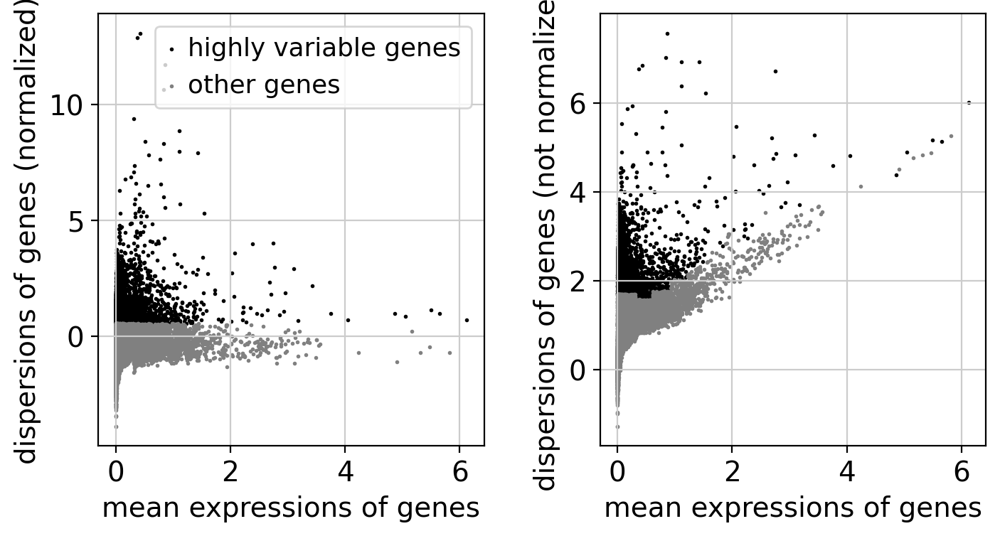

5000


AnnData object with n_obs × n_vars = 5852 × 22239
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [262]:
sc.pp.highly_variable_genes(adata_sub, n_top_genes=5000)
sc.pl.highly_variable_genes(adata_sub)
print(sum(adata_sub.var.highly_variable))
adata_sub

In [263]:
adata_sub.raw=adata_sub

In [264]:
adata_sub = adata_sub[:, adata_sub.var.highly_variable]
adata_sub

View of AnnData object with n_obs × n_vars = 5852 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [265]:
sc.pp.regress_out(adata_sub, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=96)
sc.pp.scale(adata_sub, max_value=10)
adata_sub

regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']


/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:672: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


    sparse input is densified and may lead to high memory use
    finished (0:00:28)


AnnData object with n_obs × n_vars = 5852 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [266]:
sc.tl.pca(adata_sub, svd_solver='arpack')
sce.pp.harmony_integrate(adata_sub, key='sample', basis='X_pca', adjusted_basis='X_pca_harmony')
adata_sub.obsm['X_pca']=adata_sub.obsm['X_pca_harmony']
sc.pp.neighbors(adata_sub, n_neighbors=15, n_pcs=50, knn=True)
sc.tl.leiden(adata_sub, resolution=1, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata_sub)
adata_sub

computing PCA
    with n_comps=50
    finished (0:00:09)


2025-10-24 00:15:16,185 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-10-24 00:15:18,504 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-10-24 00:15:18,561 - harmonypy - INFO - Iteration 1 of 10
2025-10-24 00:15:20,045 - harmonypy - INFO - Iteration 2 of 10
2025-10-24 00:15:21,576 - harmonypy - INFO - Iteration 3 of 10
2025-10-24 00:15:22,960 - harmonypy - INFO - Iteration 4 of 10
2025-10-24 00:15:24,165 - harmonypy - INFO - Iteration 5 of 10
2025-10-24 00:15:25,223 - harmonypy - INFO - Iteration 6 of 10
2025-10-24 00:15:26,634 - harmonypy - INFO - Iteration 7 of 10
2025-10-24 00:15:27,846 - harmonypy - INFO - Iteration 8 of 10
2025-10-24 00:15:28,905 - harmonypy - INFO - Iteration 9 of 10
2025-10-24 00:15:29,762 - harmonypy - INFO - Converged after 9 iterations


computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 30 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:07)


AnnData object with n_obs × n_vars = 5852 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

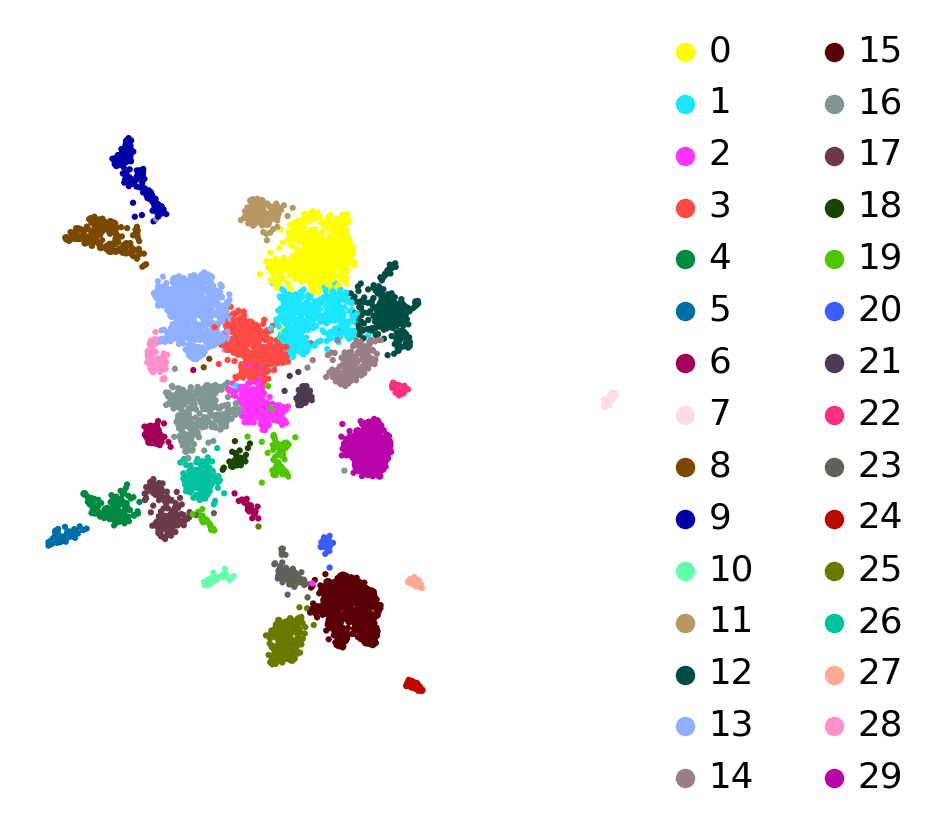

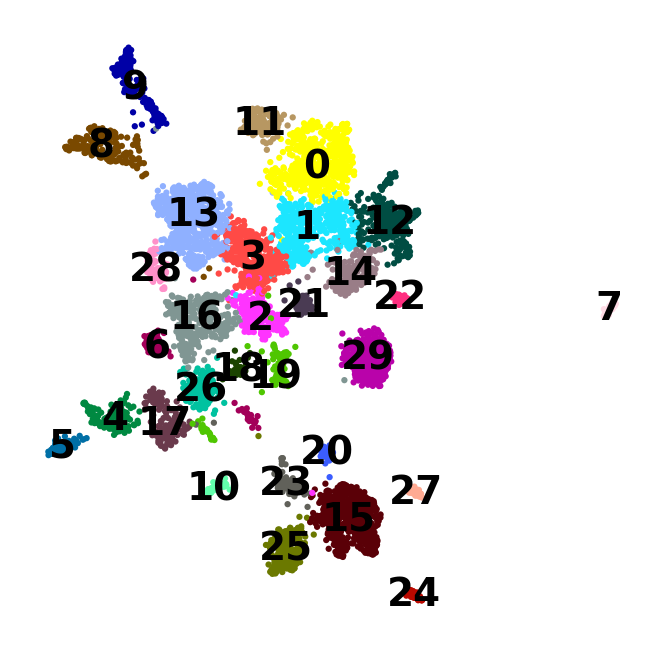

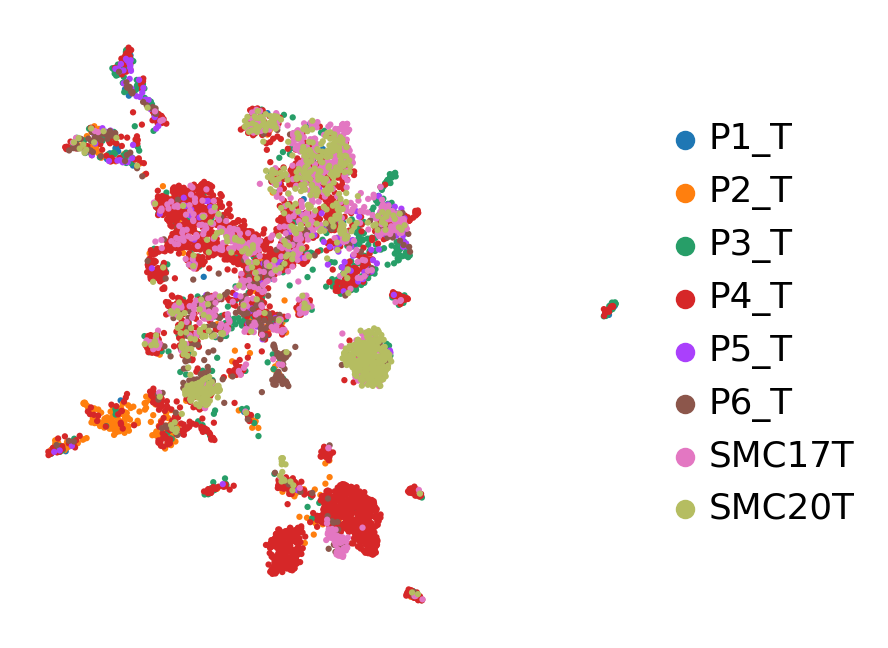

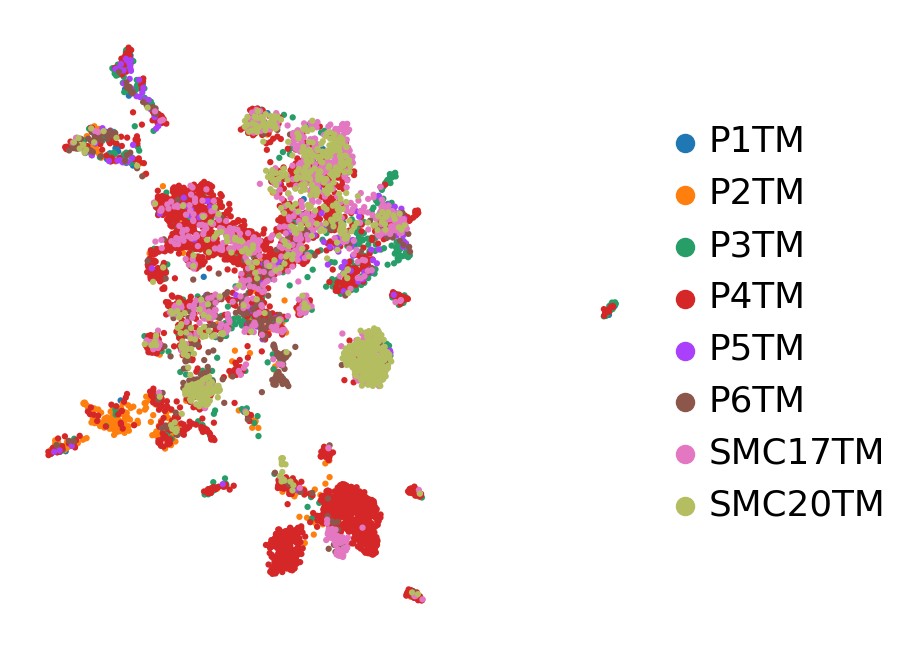

In [267]:
sc.pl.umap(adata_sub, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=True)
sc.pl.umap(adata_sub, color=['leiden'], legend_loc='on data', frameon=False, title='', use_raw=True)
sc.pl.umap(adata_sub, color=['sample'], legend_loc='right margin', frameon=False, title='', use_raw=True)
sc.pl.umap(adata_sub, color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True)

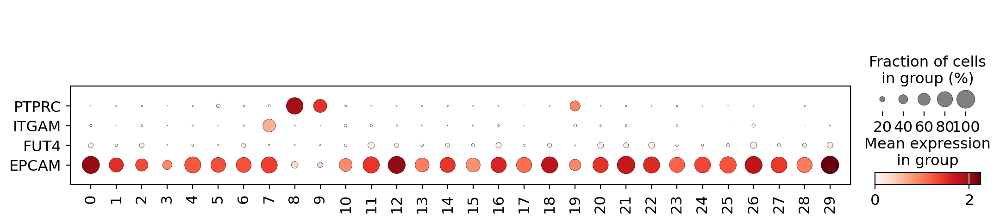

In [268]:
sc.pl.dotplot(adata_sub, var_names=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], groupby='leiden', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

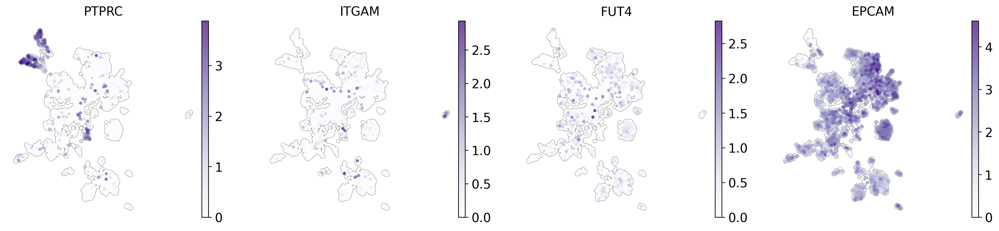

In [269]:
sc.pl.umap(adata_sub, color=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [270]:
adata_sub.write('/mnt/c/Users/hyj/Downloads/MCAD_adata_sub_1.h5ad', compression='gzip')

In [39]:
# make adata_sub2 by removing non-EPCAM+ cells

In [271]:
raw = sc.read('/mnt/c/Users/hyj/Downloads/MCAD.h5ad')
raw

AnnData object with n_obs × n_vars = 51195 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset'
    var: 'gene_ids'

In [272]:
adata_sub = sc.read('/mnt/c/Users/hyj/Downloads/MCAD_adata_sub_1.h5ad')
adata_sub

AnnData object with n_obs × n_vars = 5852 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [273]:
raw.obs['leiden']=adata_sub.obs['leiden']

In [274]:
adata_sub2=raw[raw.obs['leiden'].isin(['0', '1', '2', '3', '4', '5', '6', '10', '11', '12', '13', '14', '15', '16', '17', '18', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29'])]
adata_sub2

View of AnnData object with n_obs × n_vars = 5365 × 38606
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden'
    var: 'gene_ids'

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


normalizing counts per cell
    finished (0:00:00)


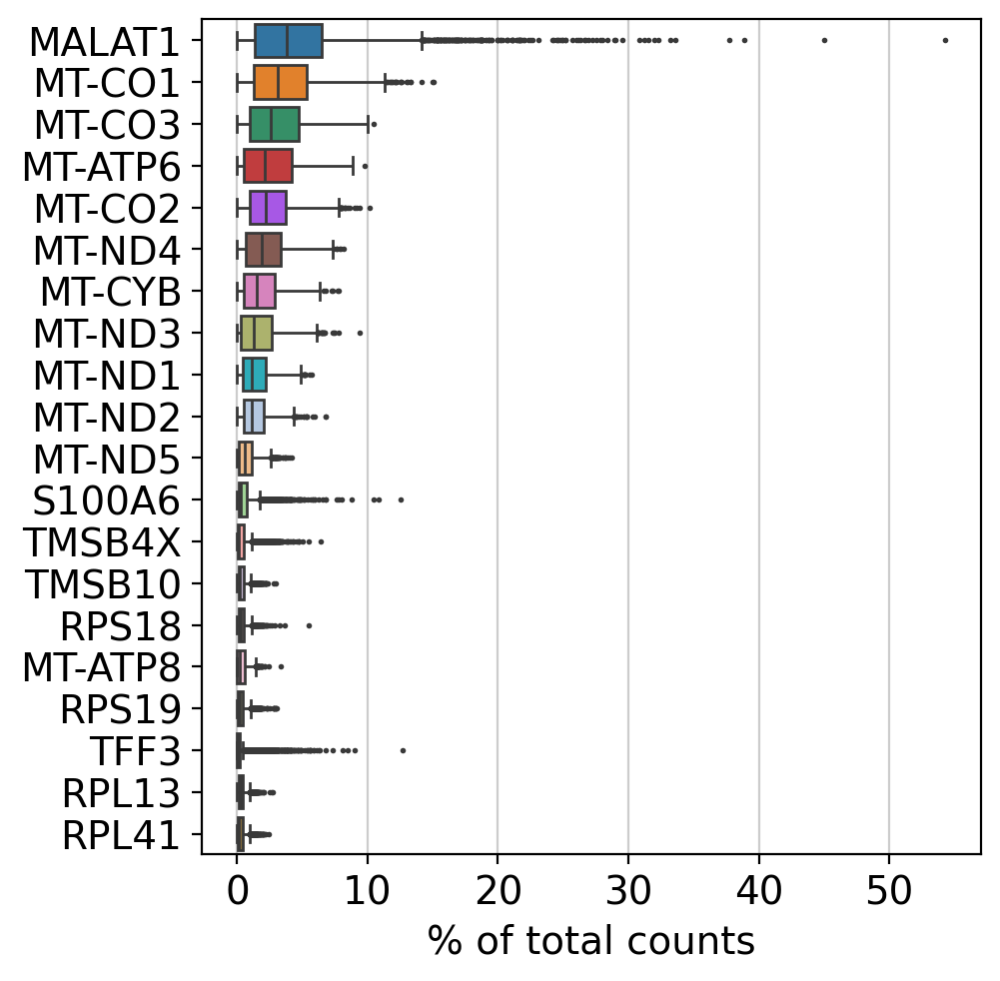

filtered out 16984 genes that are detected in less than 25 cells


AnnData object with n_obs × n_vars = 5365 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells'

In [275]:
sc.pl.highest_expr_genes(adata_sub2, n_top=20)
sc.pp.filter_cells(adata_sub2, min_genes=100)
sc.pp.filter_genes(adata_sub2, min_cells=25)
adata_sub2

In [276]:
adata_sub2.var['mt'] = adata_sub2.var_names.str.startswith('MT-')
adata_sub2.var['rpl'] = adata_sub2.var_names.str.startswith('RPL')
adata_sub2.var['rps'] = adata_sub2.var_names.str.startswith('RPS')
adata_sub2

AnnData object with n_obs × n_vars = 5365 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps'

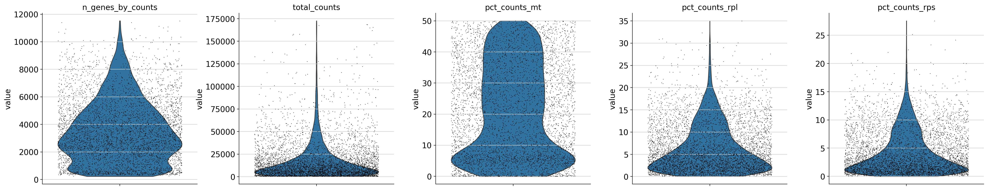

AnnData object with n_obs × n_vars = 5365 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [277]:
sc.pp.calculate_qc_metrics(adata_sub2, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata_sub2, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)
adata_sub2

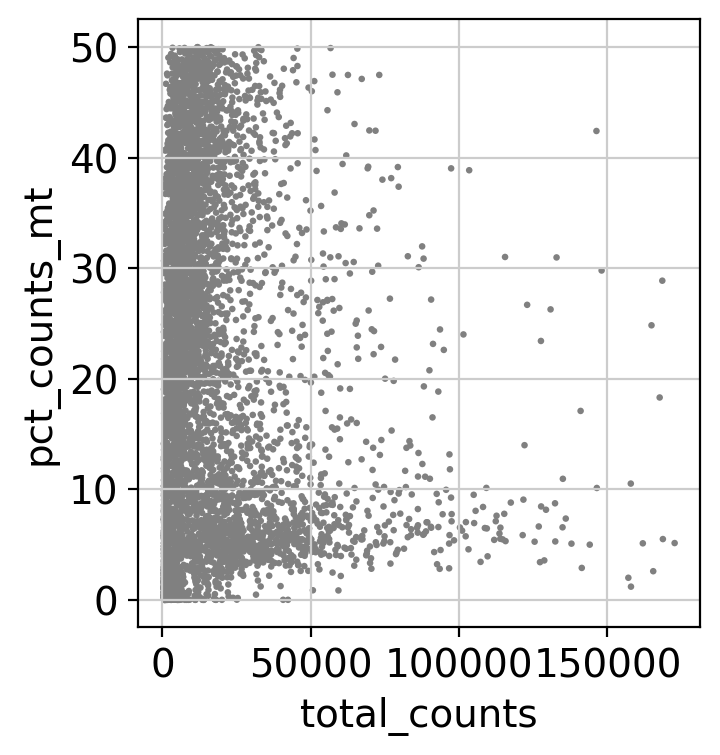

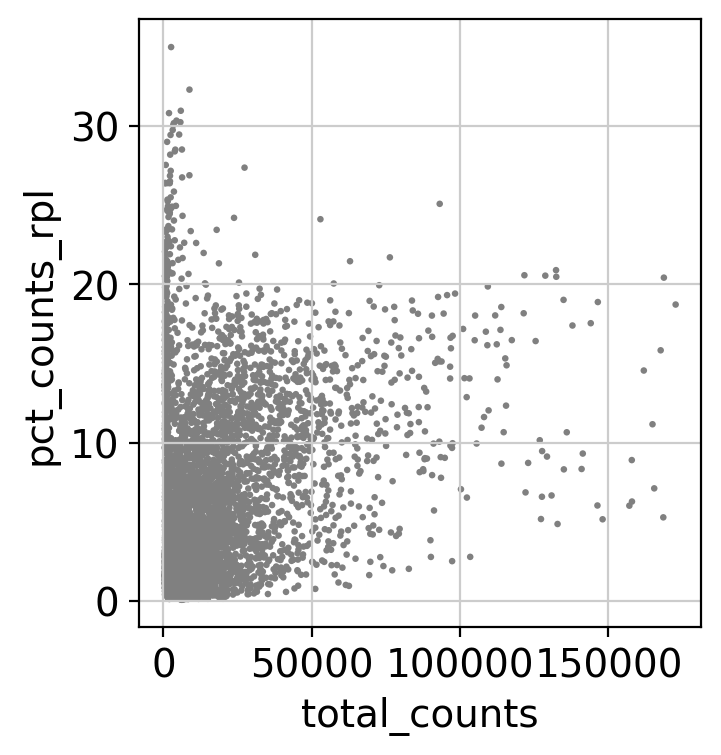

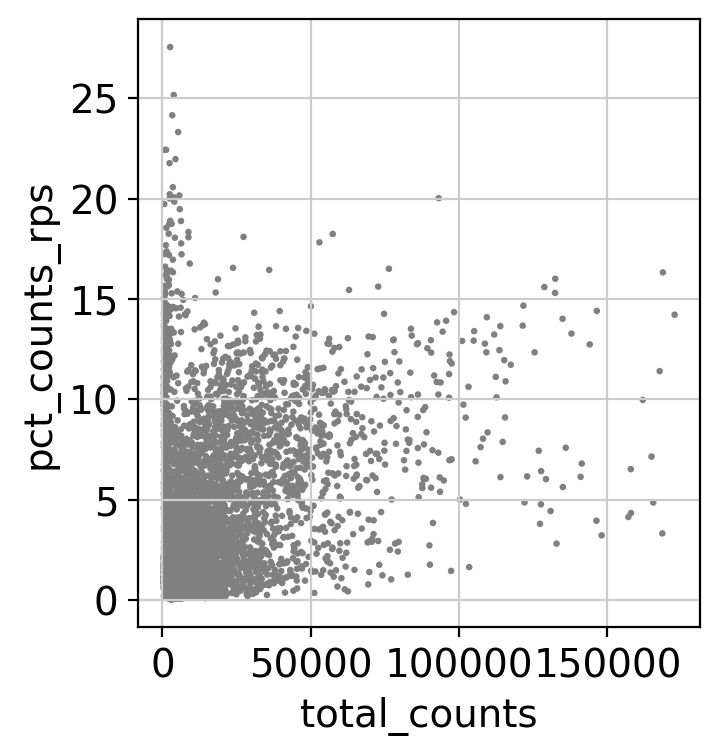

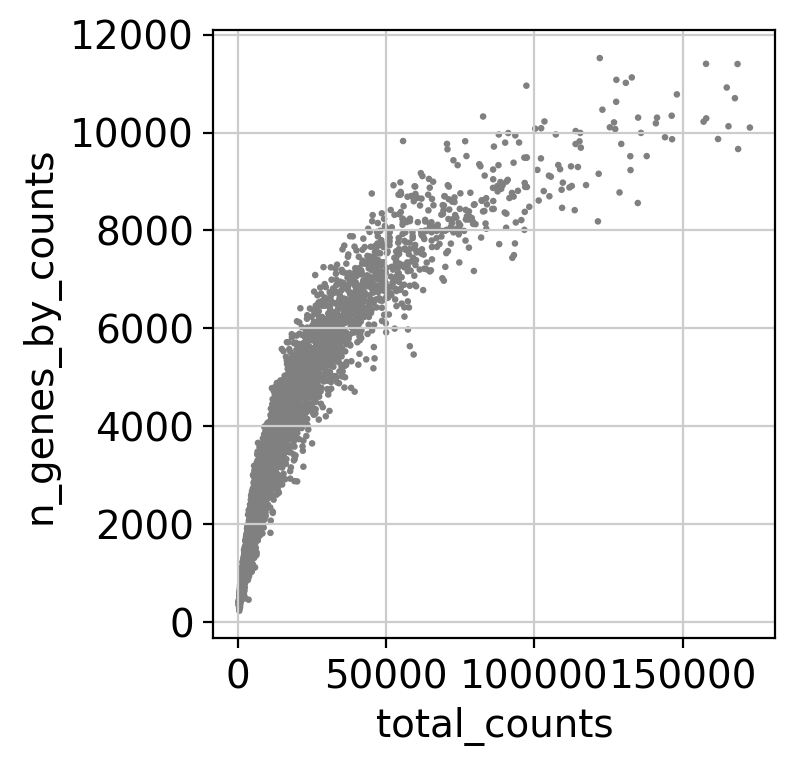

In [278]:
sc.pl.scatter(adata_sub2, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata_sub2, x='total_counts', y='pct_counts_rpl')
sc.pl.scatter(adata_sub2, x='total_counts', y='pct_counts_rps')
sc.pl.scatter(adata_sub2, x='total_counts', y='n_genes_by_counts')

In [279]:
adata_sub2 = adata_sub2[adata_sub2.obs.n_genes_by_counts < 12000, :]
adata_sub2 = adata_sub2[adata_sub2.obs.pct_counts_mt < 50, :]
adata_sub2 = adata_sub2[adata_sub2.obs.pct_counts_rpl < 50, :]
adata_sub2 = adata_sub2[adata_sub2.obs.pct_counts_rps < 50, :]
adata_sub2

View of AnnData object with n_obs × n_vars = 5364 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [280]:
sc.pp.normalize_total(adata_sub2, target_sum=1e4)
sc.pp.log1p(adata_sub2)
adata_sub2

normalizing counts per cell
    finished (0:00:00)


/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


AnnData object with n_obs × n_vars = 5364 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


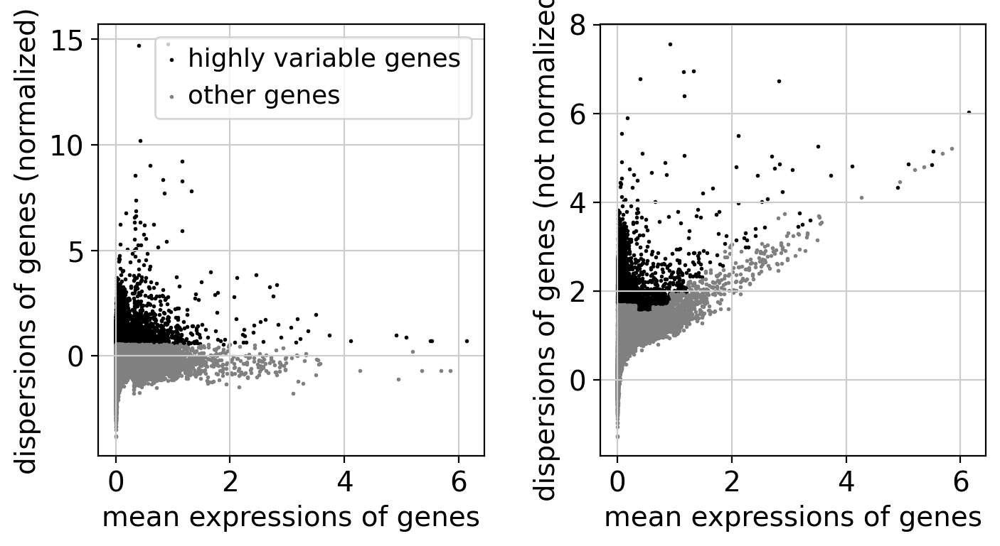

5000


AnnData object with n_obs × n_vars = 5364 × 21622
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [281]:
sc.pp.highly_variable_genes(adata_sub2, n_top_genes=5000)
sc.pl.highly_variable_genes(adata_sub2)
print(sum(adata_sub2.var.highly_variable))
adata_sub2

In [282]:
adata_sub2.raw=adata_sub2

In [283]:
adata_sub2 = adata_sub2[:, adata_sub2.var.highly_variable]
adata_sub2

View of AnnData object with n_obs × n_vars = 5364 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [284]:
sc.pp.regress_out(adata_sub2, keys=['total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=96)
sc.pp.scale(adata_sub2, max_value=10)
adata_sub2

regressing out ['total_counts', 'pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']
    sparse input is densified and may lead to high memory use


/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:672: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


    finished (0:00:20)


AnnData object with n_obs × n_vars = 5364 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg'

In [285]:
sc.tl.pca(adata_sub2, svd_solver='arpack')
sce.pp.harmony_integrate(adata_sub2, key='sample', basis='X_pca', adjusted_basis='X_pca_harmony')
adata_sub2.obsm['X_pca']=adata_sub2.obsm['X_pca_harmony']
sc.pp.neighbors(adata_sub2, n_neighbors=15, n_pcs=50, knn=True)
sc.tl.leiden(adata_sub2, resolution=0.5, flavor="igraph", n_iterations=2, directed=False)
sc.tl.umap(adata_sub2)
adata_sub2

computing PCA
    with n_comps=50
    finished (0:00:10)


2025-10-24 00:21:37,166 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-10-24 00:21:39,158 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-10-24 00:21:39,190 - harmonypy - INFO - Iteration 1 of 10
2025-10-24 00:21:40,401 - harmonypy - INFO - Iteration 2 of 10
2025-10-24 00:21:41,640 - harmonypy - INFO - Iteration 3 of 10
2025-10-24 00:21:43,256 - harmonypy - INFO - Iteration 4 of 10
2025-10-24 00:21:44,565 - harmonypy - INFO - Iteration 5 of 10
2025-10-24 00:21:45,661 - harmonypy - INFO - Iteration 6 of 10
2025-10-24 00:21:46,548 - harmonypy - INFO - Iteration 7 of 10
2025-10-24 00:21:47,541 - harmonypy - INFO - Iteration 8 of 10
2025-10-24 00:21:48,579 - harmonypy - INFO - Iteration 9 of 10
2025-10-24 00:21:49,705 - harmonypy - INFO - Iteration 10 of 10
2025-10-24 00:21:50,592 - harmonypy - INFO - Stopped before convergence


computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 22 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:06)


AnnData object with n_obs × n_vars = 5364 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

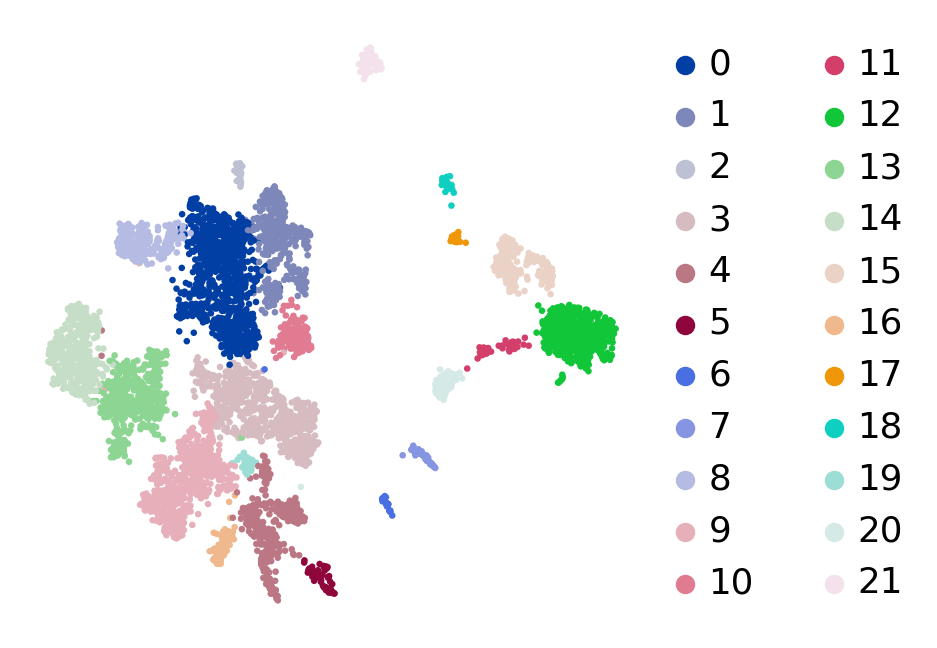

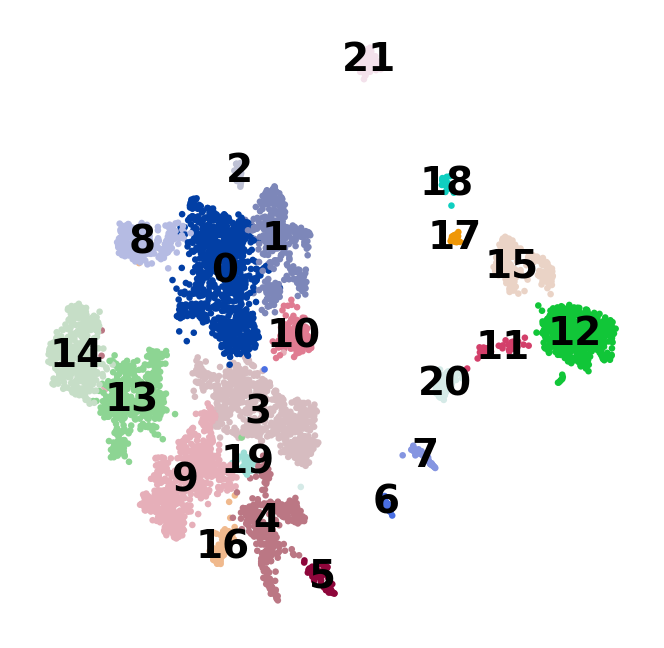

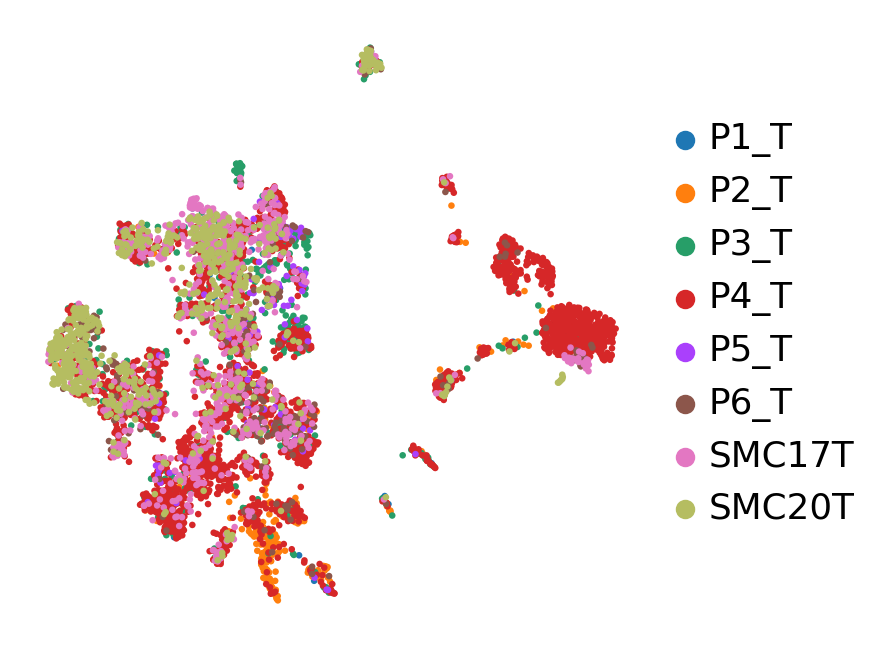

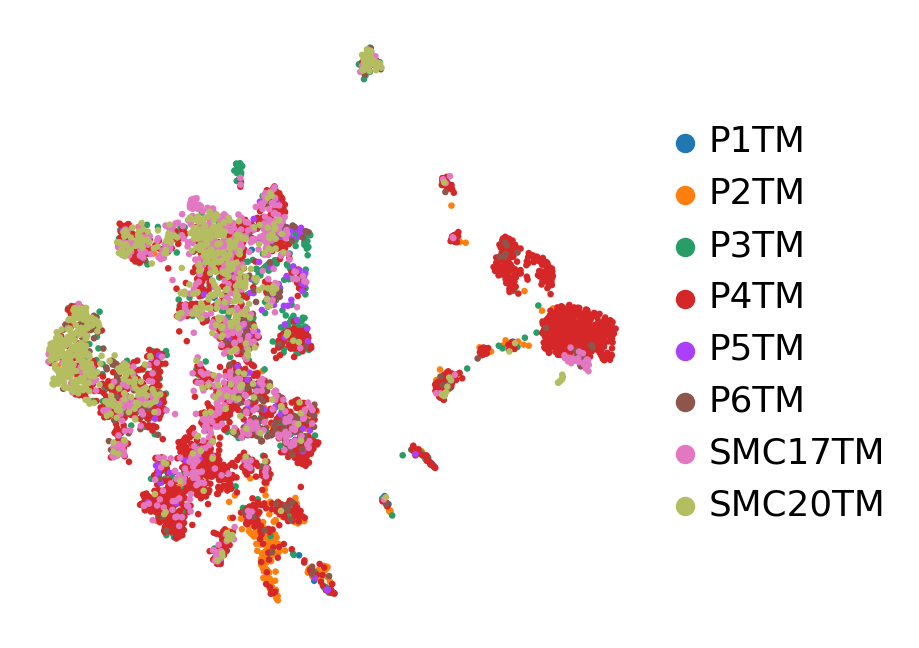

In [286]:
sc.pl.umap(adata_sub2, color=['leiden'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='8.pdf')
sc.pl.umap(adata_sub2, color=['leiden'], legend_loc='on data', frameon=False, title='', use_raw=True)
sc.pl.umap(adata_sub2, color=['sample'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='13.pdf')
sc.pl.umap(adata_sub2, color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='9.pdf')

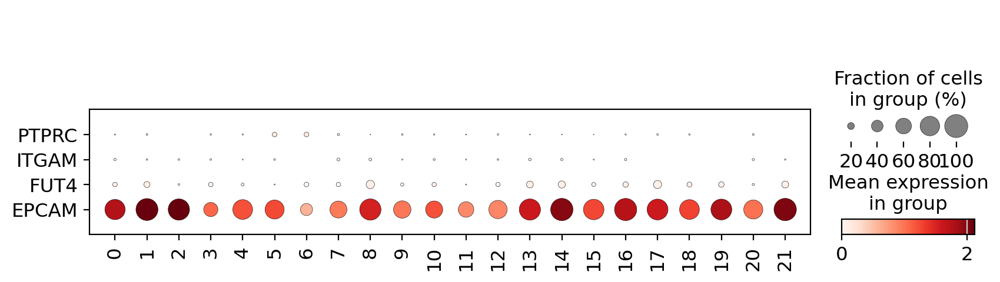

In [287]:
sc.pl.dotplot(adata_sub2, var_names=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], groupby='leiden', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

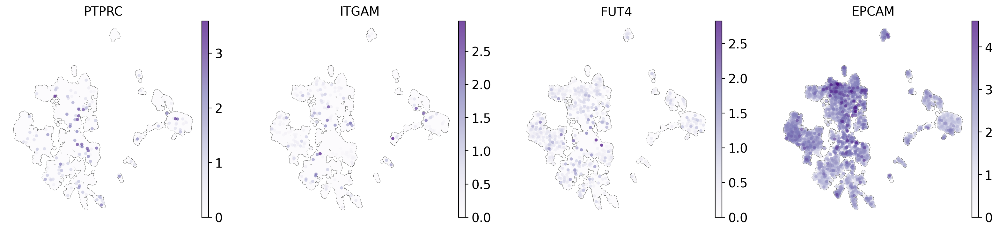

In [288]:
sc.pl.umap(adata_sub2, color=['PTPRC', 'ITGAM', 'FUT4', 'EPCAM'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [293]:
# Define use_raw, consistent with the setting in dotplot
use_raw = True
        
# Extract expression data of the CRACD gene in each group
if use_raw:
    expr_matrix = adata_sub2.raw.X  # Raw expression matrix (may be a sparse matrix)
    gene_idx = adata_sub2.raw.var_names.get_loc('CRACD')  # Index of the gene in the raw matrix
else:
    expr_matrix = adata_sub2.X  # Normalized expression matrix
    gene_idx = adata_sub2.var_names.get_loc('CRACD')
        
# Calculate by patient groups
patient_groups = adata_sub2.obs.groupby('patient')
expr_stats = []  # Store statistical results for each patient
        
for group_name, group_indices in patient_groups.indices.items():
    # Extract CRACD expression values in all cells of this patient
    group_expr = expr_matrix[group_indices, gene_idx]
    
    # Convert to dense array if it's a sparse matrix (for easier calculation)
    if hasattr(group_expr, 'toarray'):
        group_expr = group_expr.toarray().flatten()
    else:
        group_expr = group_expr.flatten()  # Ensure it's a 1D array
    
    # Calculate mean expression level
    mean_expr = group_expr.mean()
    
    # Calculate the proportion of expressing cells (usually "expressing" is defined as expression value > 0)
    total_cells = len(group_expr)  # Total number of cells in this patient
    expressed_cells = sum(group_expr > 0)  # Number of cells expressing CRACD (threshold can be adjusted as needed)
    expr_ratio = expressed_cells / total_cells * 100  # Convert to percentage (%)
    
    # Store results
    expr_stats.append({
        'patient': group_name,
        'mean_expression': mean_expr,
        'expressed_cells': expressed_cells,
        'total_cells': total_cells,
        'expression_ratio(%)': round(expr_ratio, 2)  # Keep two decimal places
    })
        
# Convert to DataFrame and sort by mean expression in descending order
result_df = pd.DataFrame(expr_stats)
result_df = result_df.sort_values(by='mean_expression', ascending=False)

# Display results
result_df

/tmp/ipykernel_1040152/363088597.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_groups = adata_sub2.obs.groupby('patient')


,patient,mean_expression,expressed_cells,total_cells,expression_ratio(%)
0,SMC20TM,0.551958,475,728,65.25
1,P3TM,0.441890,194,487,39.84
2,P4TM,0.423332,1219,2600,46.88
3,P2TM,0.290900,101,319,31.66
4,SMC17TM,0.245608,322,836,38.52
5,P1TM,0.228800,7,40,17.50
6,P6TM,0.207776,57,252,22.62
7,P5TM,0.146001,22,102,21.57


In [290]:
adata_sub2.obs['patient'] = adata_sub2.obs['patient'].cat.reorder_categories(['SMC20TM', 'P3TM', 'P4TM', 'P2TM', 'SMC17TM', 'P1TM', 'P6TM', 'P5TM'])

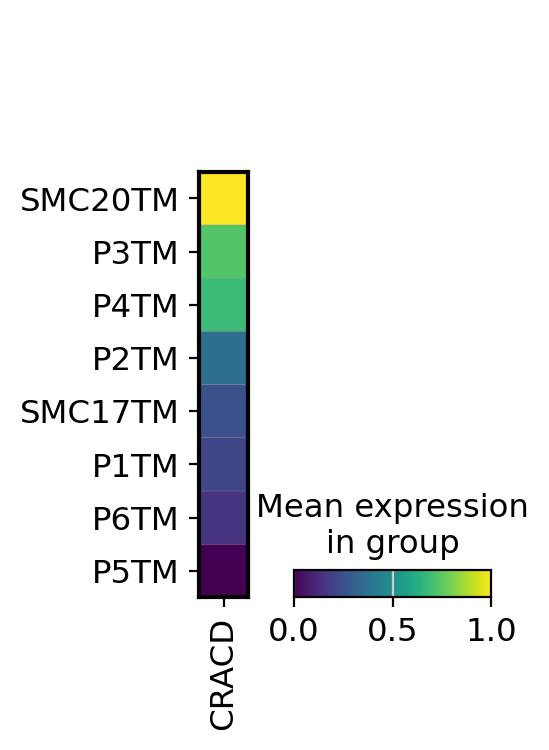

In [294]:
sc.pl.matrixplot(adata_sub2, var_names=['CRACD'], groupby='patient', use_raw=True, dendrogram=False, cmap='viridis', standard_scale='var', swap_axes=False, save='27.pdf')

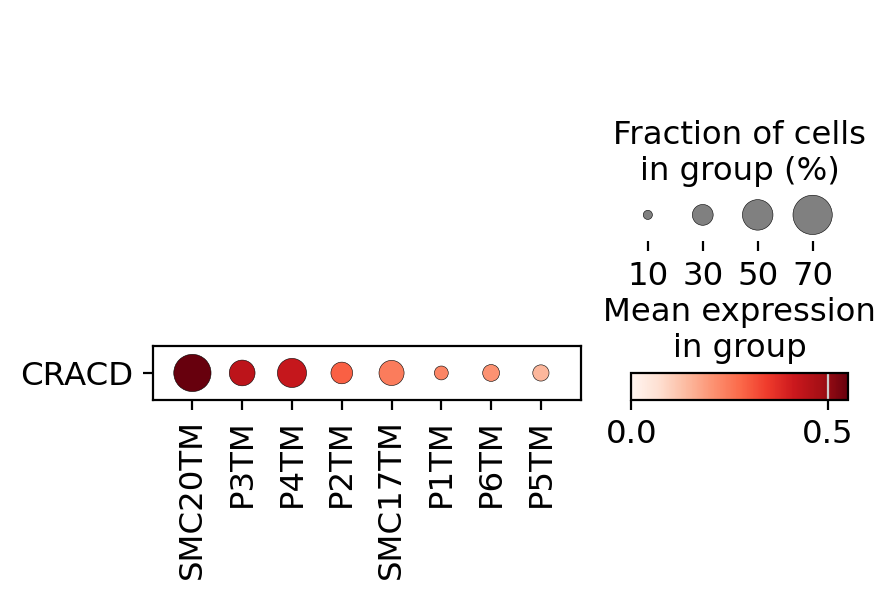

In [310]:
sc.pl.dotplot(adata_sub2, var_names=['CRACD'], groupby='patient', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0, save='27.pdf')

In [296]:
adata_sub2.obs['cracd'] = (adata_sub2.obs['patient'].map
                   (lambda x: {'P1TM':'low', 'P2TM':'high', 'P3TM':'high', 'P4TM':'high', 'P5TM':'low', 'P6TM':'low',
                               'SMC17TM': 'low', 'SMC20TM': 'high'}.get(x, x)).astype("category"))
adata_sub2

AnnData object with n_obs × n_vars = 5364 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'cracd'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'sample_colors', 'patient_colors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [297]:
adata_sub2.obs['cracd'].value_counts().sort_index()

cracd
high    4134
low     1230
Name: count, dtype: int64

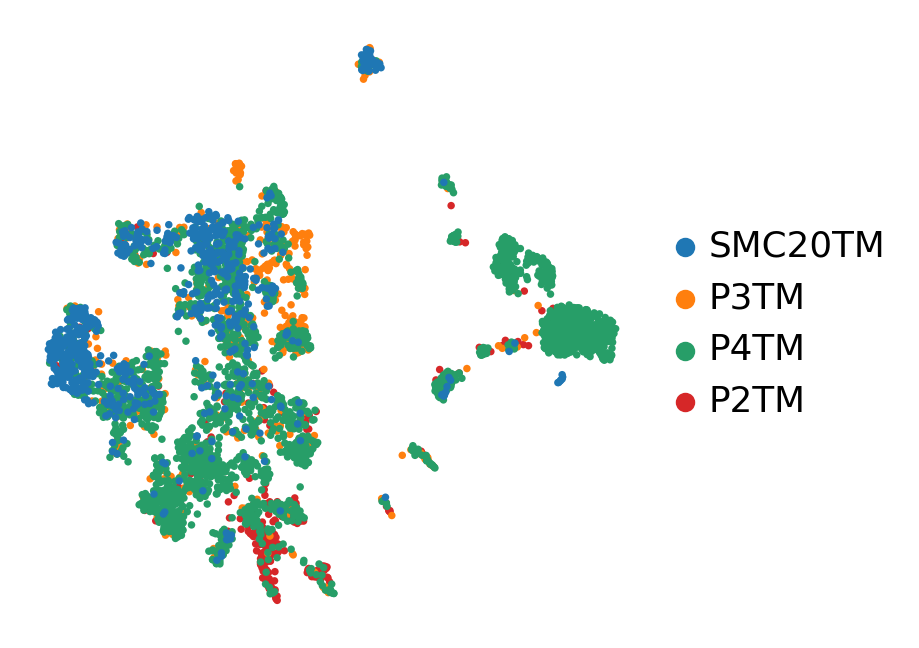

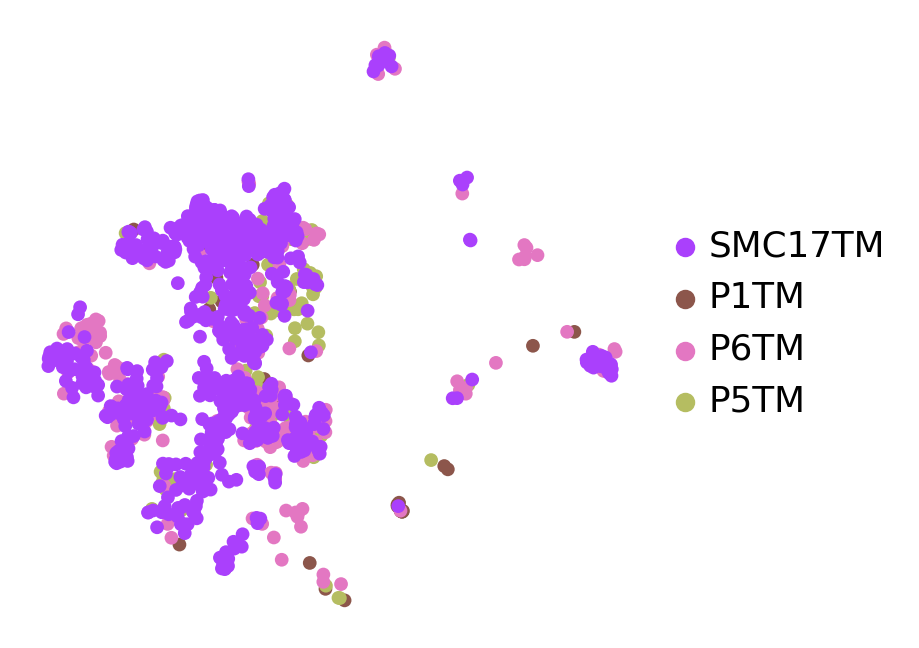

In [320]:
sc.pl.umap(adata_sub2[adata_sub2.obs['cracd'].isin(['high'])], color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='3.pdf')
sc.pl.umap(adata_sub2[adata_sub2.obs['cracd'].isin(['low'])], color=['patient'], legend_loc='right margin', frameon=False, title='', use_raw=True, save='2.pdf')

/home/hyj/anaconda3/envs/py311/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:2051: FutureWarning: Use obs (e.g. `k in adata.obs` or `str(adata.obs.columns.tolist())`) instead of AnnData.obs_keys, AnnData.obs_keys is deprecated and will be removed in the future.
  if group not in list(adata.obs_keys()) + [adata.obs.index.name]:


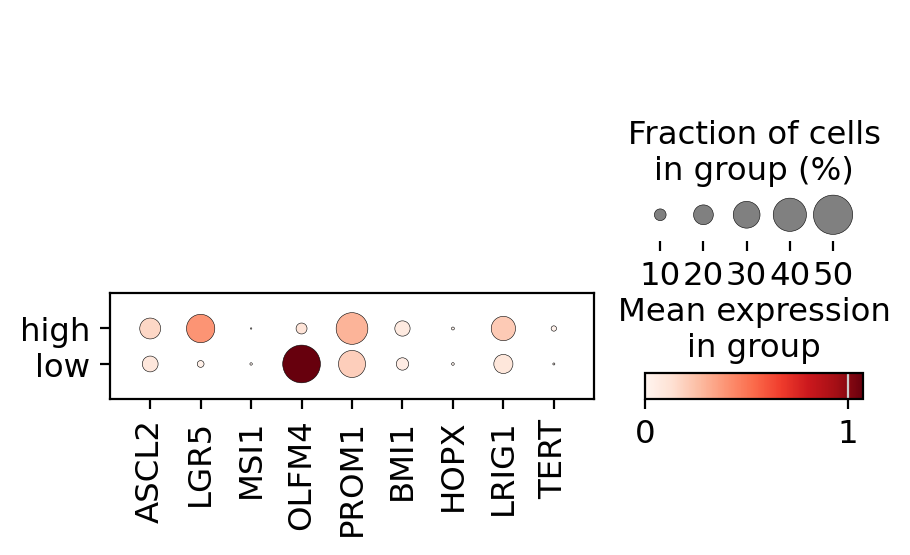

In [3]:
# Intestinal stem and progenitor cell markers
# 'ASCL2', 'LGR5', 'MSI1', 'OLFM4', 'PROM1', 'BMI1', 'HOPX', 'LRIG1', 'TERT'
sc.pl.dotplot(adata_sub2, var_names=['ASCL2', 'LGR5', 'MSI1', 'OLFM4', 'PROM1', 'BMI1', 'HOPX', 'LRIG1', 'TERT'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, save='19.pdf')

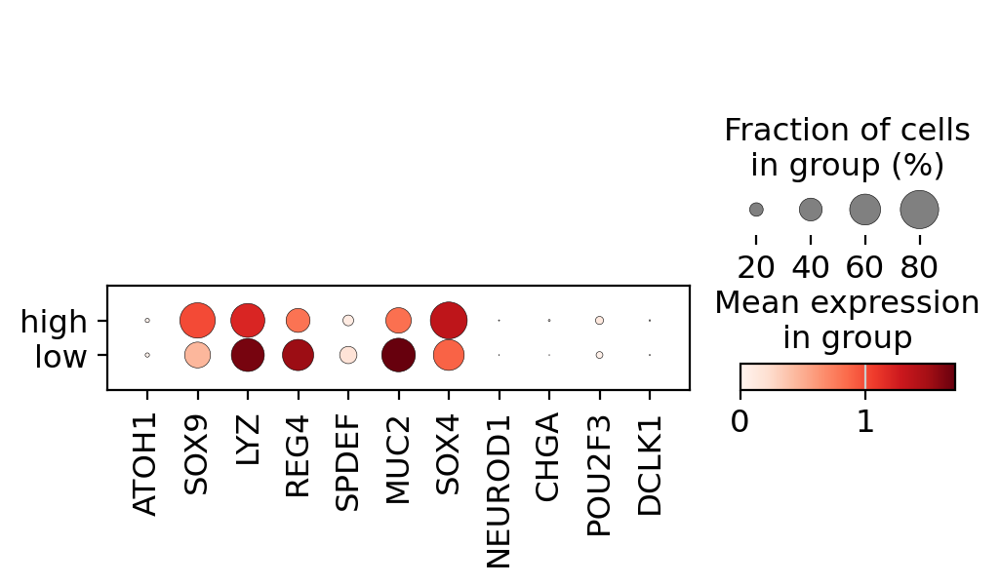

In [10]:
# Intestinal secretory lineage markers
# 'ATOH1', 'SOX9', 'LYZ', 'REG4', 'SPDEF', 'MUC2', 'SOX4', 'NEUROG3', 'NEUROD1', 'CHGA', 'POU2F3', 'DCLK1'
sc.pl.dotplot(adata_sub2, var_names=['ATOH1', 'SOX9', 'LYZ', 'REG4', 'SPDEF', 'MUC2', 'SOX4', 'NEUROD1', 'CHGA', 'POU2F3', 'DCLK1'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, save='19.pdf')

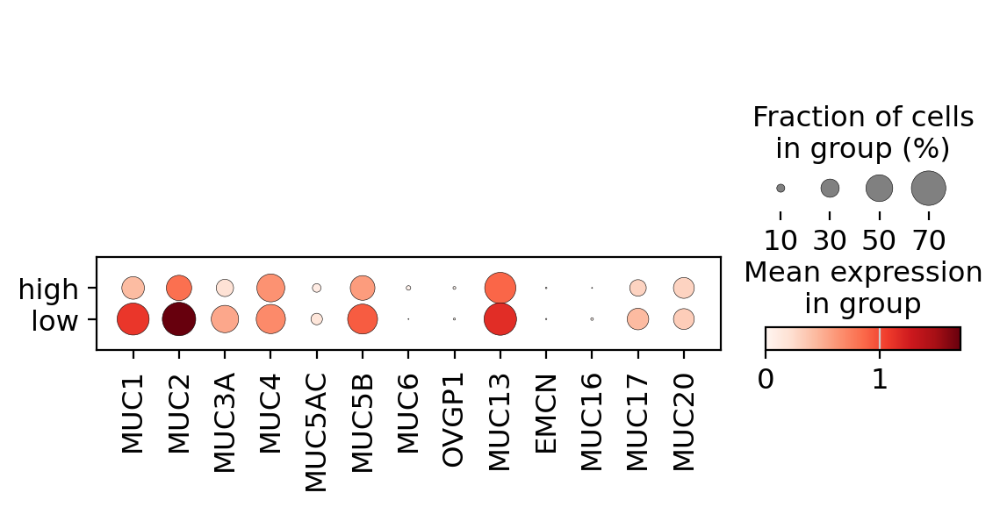

In [11]:
# Secreted mucin family
# 'MUC1', 'MUC2', 'MUC3A', 'MUC4', 'MUC5AC', 'MUC5B', 'MUC6', 'MUC7', 'OVGP1', 'MUC13', 'EMCN', 'MUC15', 'MUC16', 'MUC17', 'MUC19', 'MUC20'
sc.pl.dotplot(adata_sub2, var_names=['MUC1', 'MUC2', 'MUC3A', 'MUC4', 'MUC5AC', 'MUC5B', 'MUC6', 'OVGP1', 'MUC13', 'EMCN', 'MUC16', 'MUC17', 'MUC20'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, save='20.pdf')

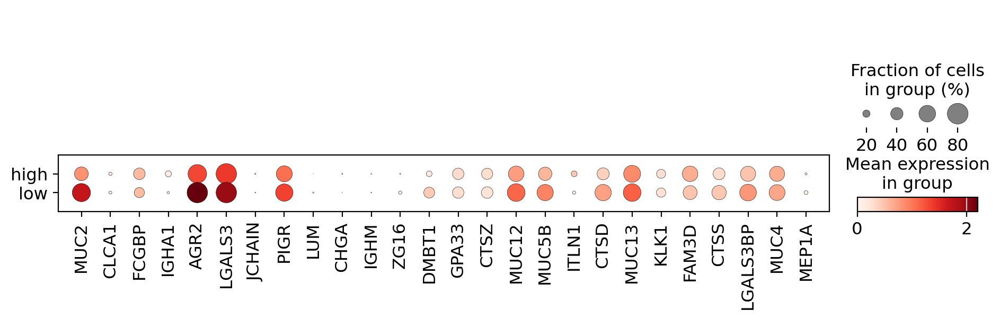

In [12]:
# Human colon mucus proteins
# 'MUC2', 'CLCA1', 'FCGBP', 'IGHA1', 'AGR2', 'LGALS3', 'JCHAIN', 'PIGR', 'LUM', 'CHGA', 'IGHM', 'DCN', 'ZG16', 'DMBT1', 'GPA33', 'CTSZ', 'MUC12', 'MUC5B', 'ITLN1', 'RNASE3', 'EPX', 'CTSD', 'MUC13', 'KLK1', 'FAM3D', 'CTSS', 'LGALS3BP', 'MUC4', 'MEP1A'
sc.pl.dotplot(adata_sub2, var_names=['MUC2', 'CLCA1', 'FCGBP', 'IGHA1', 'AGR2', 'LGALS3', 'JCHAIN', 'PIGR', 'LUM', 'CHGA', 'IGHM', 'ZG16', 'DMBT1', 'GPA33', 'CTSZ', 'MUC12', 'MUC5B', 'ITLN1', 'CTSD', 'MUC13', 'KLK1', 'FAM3D', 'CTSS', 'LGALS3BP', 'MUC4', 'MEP1A'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, save='21.pdf')

In [4]:
sc.tl.rank_genes_groups(adata_sub2, groupby='cracd', reference='high', method='t-test', use_raw=True)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)


In [5]:
result = adata_sub2.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).to_csv("/mnt/c/Users/hyj/Downloads/MCAD_cracd_low_vs_high_markers.csv")

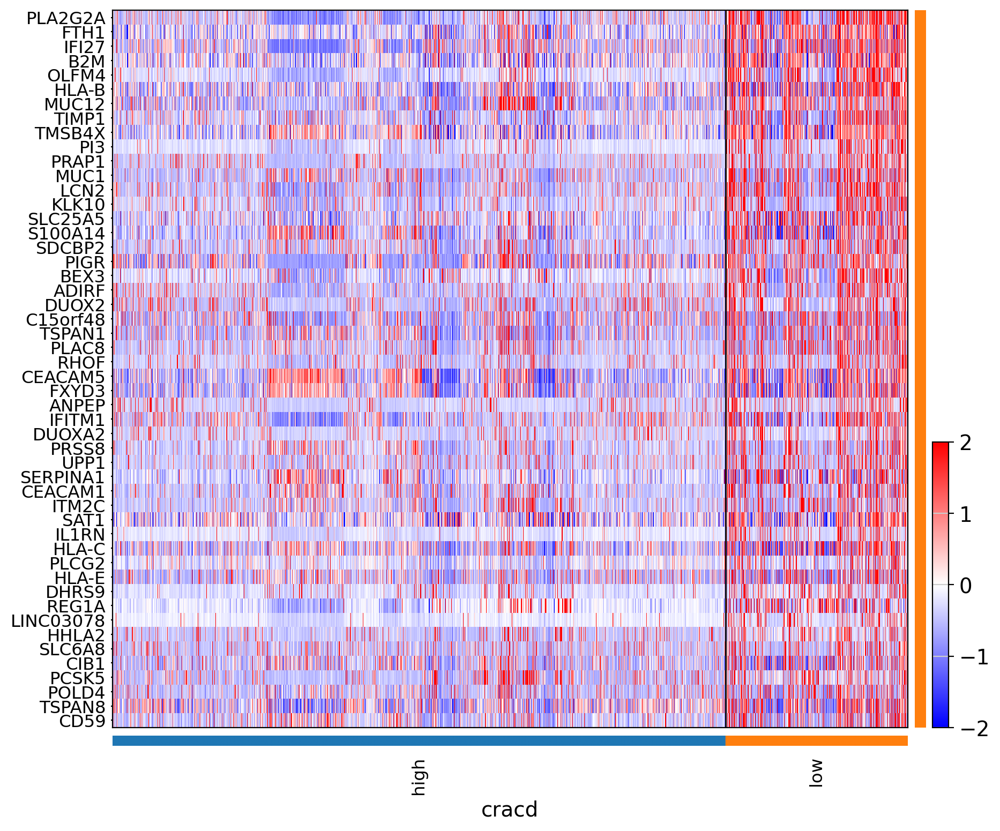

In [17]:
sc.pl.rank_genes_groups_heatmap(adata_sub2, n_genes=50, groupby='cracd', use_raw=False, swap_axes=True, show_gene_labels=True, vmin=-2, vmax=2, cmap='bwr', dendrogram=False, save='15.pdf')

In [ ]:
# CRACD_high top 1-50 genes
CRACD_high_top50=['ENSG00000289474', 'SLC35F1', 'NALF1', 'GOLGA8A', 'HES1', 'MT-ATP8', 'LGR5', 'IER5L', 'H19', 'NIHCOLE', 'CST6', 'FGGY', 'CDKN1C', 'RPL23', 'DNAH14', 'ANKRD36', 'RABL6', 'SNTB1', 'TMEM238', 'BOD1L1', 'BMP4', 'LINC02432', 'SLCO3A1', 'SLC2A1', 'LRP4', 'MTAP', 'NKTR', 'CASC9', 'HES6', 'NKD1', 'ADAMTS19', 'NDRG1', 'KCNH8', 'STYXL2', 'ENSG00000289136', 'ZNF521', 'ENSG00000259001', 'ANKRD36C', 'PCED1B', 'AKAP12', 'PLCB1', 'LINC00342', 'KNOP1', 'GPCPD1', 'POLR2A', 'FBXL2', 'ENSG00000227486', 'ZC3H12B', 'ITGA9', 'KIF26B']
sc.pl.dotplot(adata_sub2, var_names=CRACD_high_top50, groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, dot_min=0)
# CRACD_high top 51-100 genes
CRACD_high_top51_100=['MIR4713HG', 'SCMH1', 'CSRNP2', 'SLC7A5', 'LINC01594', 'RRAD', 'FRMD5', 'CACNB2', 'PDE4B', 'MLXIPL', 'IGFBP2', 'LINC01572', 'HUNK', 'MAP7D2', 'BMP7', 'SOX4', 'GRK3', 'GCNT1', 'ENSG00000284377', 'SCAPER', 'ENSG00000285280', 'NPSR1-AS1', 'ZNF69', 'KCNJ3', 'ALOX5', 'ENSG00000228566', 'PMEPA1', 'EDN1', 'LINC01515', 'DPEP1', 'ZFPM1', 'ZRANB3', 'ENSG00000291175', 'PRKDC', 'SLC22A3', 'ABHD8', 'ITPR2', 'UPRT', 'CHRNA7', 'TIMP3', 'IGFBPL1', 'IL1RAPL2', 'FOXC2-AS1', 'PGGHG', 'NRCAM', 'PPL', 'H2AC20', 'LINC02994', 'HIBCH', 'ENSG00000227088']
sc.pl.dotplot(adata_sub2, var_names=CRACD_high_top51_100, groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, dot_min=0)

In [ ]:
# remove 'MT-ATP8', 'RPL23'
CRACD_high_signature=['ENSG00000289474', 'SLC35F1', 'NALF1', 'GOLGA8A', 'HES1','LGR5', 'IER5L', 'H19', 'NIHCOLE', 'CST6', 'FGGY', 'CDKN1C','DNAH14', 'ANKRD36', 'RABL6', 'SNTB1', 'TMEM238', 'BOD1L1', 'BMP4', 'LINC02432', 'SLCO3A1', 'SLC2A1', 'LRP4', 'MTAP', 'NKTR', 'CASC9', 'HES6', 'NKD1', 'ADAMTS19', 'NDRG1', 'KCNH8', 'STYXL2', 'ENSG00000289136', 'ZNF521', 'ENSG00000259001', 'ANKRD36C', 'PCED1B', 'AKAP12', 'PLCB1', 'LINC00342', 'KNOP1', 'GPCPD1', 'POLR2A', 'FBXL2', 'ENSG00000227486', 'ZC3H12B', 'ITGA9', 'KIF26B']
sc.tl.score_genes(adata_sub2, gene_list=CRACD_high_signature, score_name='CRACD_high_signature', use_raw=True)
sc.pl.dotplot(adata_sub2, var_names=['CRACD_high_signature'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, cmap='inferno', save='23.pdf')

In [ ]:
max(list(adata_sub2.obs['CRACD_high_signature']))

In [ ]:
min(list(adata_sub2.obs['CRACD_high_signature']))

In [ ]:
sc.pl.umap(adata_sub2, color=['CRACD_high_signature'],
           legend_loc='right margin', frameon=False, vmin=-0.24, vmax=0.87, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='inferno', save='24.pdf')

In [ ]:
sc.pl.matrixplot(adata_sub2, var_names=['CRACD_high_signature'], groupby='patient', use_raw=True, dendrogram=False, cmap='inferno', standard_scale='var', swap_axes=True, save='27.pdf')

In [ ]:
# CRACD_low top 1-50 genes
CRACD_low_top50=['B2M', 'MUC12', 'ITM2C', 'PPDPF', 'FTH1', 'HLA-C', 'C15orf48', 'IFI27', 'LGALS4', 'HLA-B', 'TSPAN1', 'SLC25A5', 'CDHR5', 'FXYD3', 'RPL41', 'CST3', 'RHOC', 'RPS26', 'CTSD', 'SELENOP', 'S100A14', 'PLAC8', 'PI3', 'S100A6', 'MUC3A', 'LCN2', 'PLA2G2A', 'SH3BGRL3', 'SSR4', 'PHGR1', 'MYL12B', 'SLPI', 'C19orf33', 'PRSS8', 'CA2', 'SERPINA1', 'FTL', 'CEACAM6', 'MS4A12', 'SLC26A3', 'MUC1', 'CD177', 'CDKN2B-AS1', 'MT-CO2', 'TIMP1', 'PRKG1', 'GUCA2A', 'MUC2', 'AGR2', 'CD59']
sc.pl.dotplot(adata_sub2, var_names=CRACD_low_top50, groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, dot_min=0)
# CRACD_low top 51-100 genes
CRACD_low_top51_100=['SFN', 'ALDOA', 'DHRS9', 'CA1', 'PCSK5', 'OLFM4', 'IL32', 'SLC4A4', 'MUC4', 'IL2RG', 'MEP1A', 'CA4', 'NXPE1', 'MT1M', 'PDZK1IP1', 'CEACAM7', 'MT1G', 'FABP1', 'NEDD4L', 'PKIB', 'SLC26A2', 'MT1F', 'TFF3', 'CEACAM1', 'NDUFA4', 'PDE3A', 'GK', 'DUSP1', 'RPS5', 'POMP', 'TFF1', 'CDHR2', 'BCAS1', 'LYPD8', 'GSN', 'ASS1', 'MT-CO1', 'PRAP1', 'ZG16', 'XDH', 'GUCA2B', 'MT2A', 'ENSG00000273149', 'ENSG00000274213', 'HRCT1', 'RNASE1', 'MT-ND6', 'HDAC9', 'ADH1C', 'ATP2A3']
sc.pl.dotplot(adata_sub2, var_names=CRACD_low_top51_100, groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, vmin=0, dot_min=0)

In [ ]:
# remove 'MT-CO2'
CRACD_low_signature=['B2M', 'MUC12', 'ITM2C', 'PPDPF', 'FTH1', 'HLA-C', 'C15orf48', 'IFI27', 'LGALS4', 'HLA-B', 'TSPAN1', 'SLC25A5', 'CDHR5', 'FXYD3', 'RPL41', 'CST3', 'RHOC', 'RPS26', 'CTSD', 'SELENOP', 'S100A14', 'PLAC8', 'PI3', 'S100A6', 'MUC3A', 'LCN2', 'PLA2G2A', 'SH3BGRL3', 'SSR4', 'PHGR1', 'MYL12B', 'SLPI', 'C19orf33', 'PRSS8', 'CA2', 'SERPINA1', 'FTL', 'CEACAM6', 'MS4A12', 'SLC26A3', 'MUC1', 'CD177', 'CDKN2B-AS1', 'TIMP1', 'PRKG1', 'GUCA2A', 'MUC2', 'AGR2', 'CD59']
sc.tl.score_genes(adata_sub2, gene_list=CRACD_low_signature, score_name='CRACD_low_signature', use_raw=True)
sc.pl.dotplot(adata_sub2, var_names=['CRACD_low_signature'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, cmap='inferno', save='23.pdf')

In [ ]:
max(list(adata_sub2.obs['CRACD_low_signature']))

In [ ]:
min(list(adata_sub2.obs['CRACD_low_signature']))

In [ ]:
sc.pl.umap(adata_sub2, color=['CRACD_low_signature'],
           legend_loc='right margin', frameon=False, vmin=-0.48, vmax=2.52, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='inferno', save='24.pdf')

In [5]:
adata_sub2.obs['cracd']

P1_T_AACCCAAGTGCTCTCT-1_P1_T         low
P1_T_AAGTGAAAGTCTGCAT-1_P1_T         low
P1_T_AATTCCTGTACGCTAT-1_P1_T         low
P1_T_ACCACAACAACCGATT-1_P1_T         low
P1_T_ACCCTCAAGTTGTAAG-1_P1_T         low
                                    ... 
SMC20T_TTTGGTTAGGATCGCA-1_SMC20T    high
SMC20T_TTTGGTTGTTGAACTC-1_SMC20T    high
SMC20T_TTTGTCAAGGATTCGG-1_SMC20T    high
SMC20T_TTTGTCAAGTCTCCTC-1_SMC20T    high
SMC20T_TTTGTCATCACGCGGT-1_SMC20T    high
Name: cracd, Length: 5364, dtype: category
Categories (2, object): ['high', 'low']

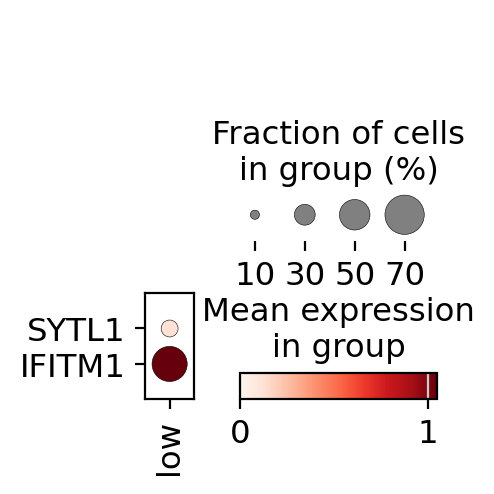

In [6]:
sc.pl.dotplot(adata_sub2[adata_sub2.obs['cracd'].isin(['low'])], var_names=['SYTL1', 'IFITM1'], groupby='cracd', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

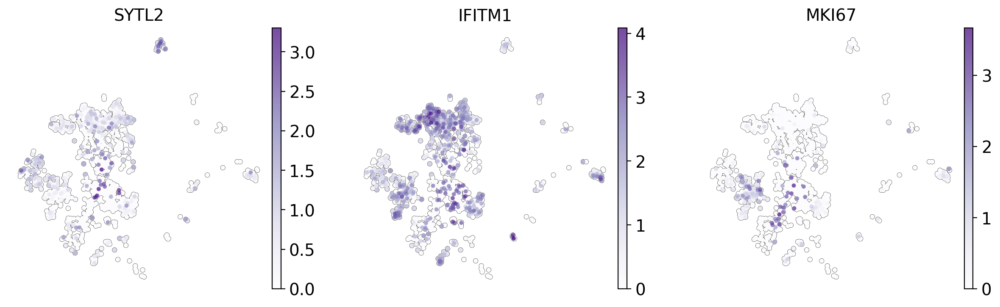

In [9]:
sc.pl.umap(adata_sub2[adata_sub2.obs['cracd'].isin(['low'])], color=['SYTL2', 'IFITM1', 'MKI67'], legend_loc='right margin', frameon=False, add_outline=True, outline_width=(0.05,0.05), size=50, use_raw=True, cmap='Purples')

In [ ]:
sc.pl.matrixplot(adata_sub2, var_names=['CRACD_low_signature'], groupby='patient', use_raw=True, dendrogram=False, cmap='inferno', standard_scale='var', swap_axes=True, save='27.pdf')

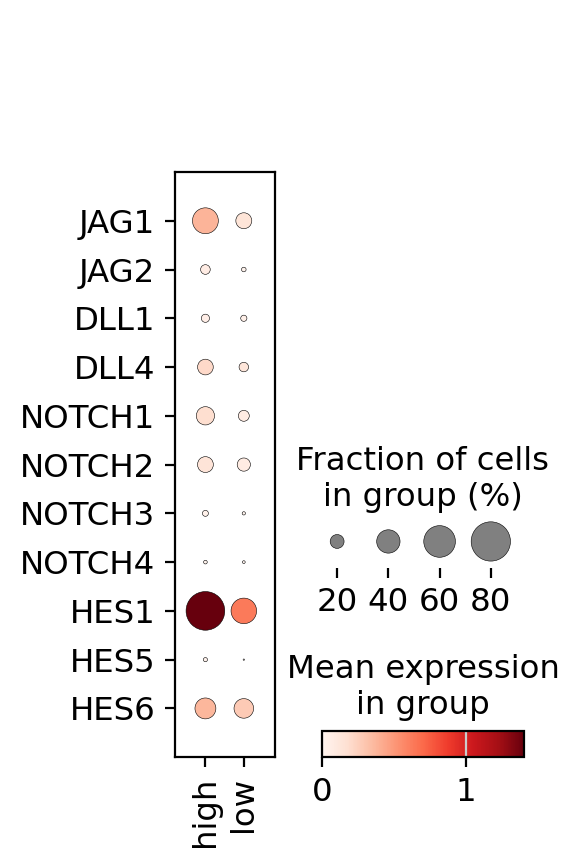

In [305]:
sc.pl.dotplot(adata_sub2, var_names=['JAG1', 'JAG2', 'DLL1', 'DLL4', 'NOTCH1', 'NOTCH2', 'NOTCH3', 'NOTCH4', 'HES1', 'HES5', 'HES6'], groupby='cracd', use_raw=True, var_group_rotation=0, vmin=0, swap_axes=True, dot_min=0)

In [306]:
NOTCH_SIGNALING=["APH1A","ARRB1","CCND1","CUL1","DLL1","DTX1","DTX2","DTX4","FBXW11","FZD1","FZD5","FZD7","HES1","HEYL","JAG1","KAT2A","LFNG","MAML2","NOTCH1","NOTCH2","NOTCH3","PPARD","PRKCA","PSEN2","PSENEN","RBX1","SAP30","SKP1","ST3GAL6","TCF7L2","WNT2","WNT5A"]

In [307]:
sc.tl.score_genes(adata_sub2, gene_list=NOTCH_SIGNALING, score_name='NOTCH_SIGNALING', use_raw=True)

computing score 'NOTCH_SIGNALING'
    finished: added
    'NOTCH_SIGNALING', score of gene set (adata.obs).
    848 total control genes are used. (0:00:00)


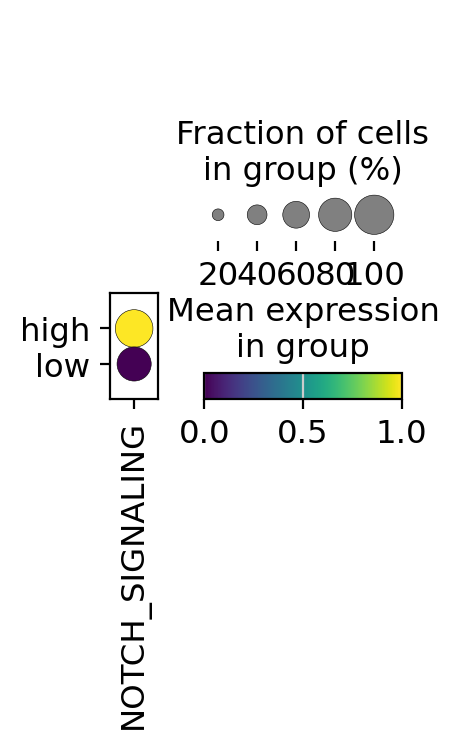

In [308]:
sc.pl.dotplot(adata_sub2, var_names=['NOTCH_SIGNALING'], groupby='cracd', use_raw=True, swap_axes=False, var_group_rotation=0, cmap='viridis', dot_min=0, dot_max=1, standard_scale='var', save='23.pdf')

In [309]:
adata_sub2.write('/mnt/c/Users/hyj/Downloads/MCAD_adata_sub2_1.h5ad', compression='gzip')

In [2]:
adata_sub2=sc.read('/mnt/c/Users/hyj/Downloads/MCAD_adata_sub2_1.h5ad')
adata_sub2

AnnData object with n_obs × n_vars = 5364 × 5000
    obs: 'doublet_score', 'predicted_doublet', 'sample', 'pathology', 'patient', 'dataset', 'leiden', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'cracd', 'NOTCH_SIGNALING'
    var: 'gene_ids', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cracd_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'rank_genes_groups', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'